In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

mydrive = Path("/content/drive/MyDrive")

print("Top-level folders:")
for item in mydrive.iterdir():
    print("-", item.name)

paths = {
    "RARE26": mydrive / "RARE26",
    "RARE26 dataset": mydrive / "RARE26" / "dataset",
    "RARE26 splits": mydrive / "RARE26" / "splits",
    "train_colab.csv": mydrive / "RARE26" / "splits" / "train_colab.csv",
    "validation_colab.csv": mydrive / "RARE26" / "splits" / "validation_colab.csv",
    "test_colab.csv": mydrive / "RARE26" / "splits" / "test_colab.csv",
    "RARE25 zip": mydrive / "RARE26" / "dataset" / "RARE25-train-data.zip",
    "RARE26 Phase2": mydrive / "RARE26 Phase2",
}

print("\nRequired paths check:")
for name, path in paths.items():
    print(name, ":", path.exists(), "|", path)

Top-level folders:
- RARE26
- RARE26 Phase2

Required paths check:
RARE26 : True | /content/drive/MyDrive/RARE26
RARE26 dataset : True | /content/drive/MyDrive/RARE26/dataset
RARE26 splits : True | /content/drive/MyDrive/RARE26/splits
train_colab.csv : True | /content/drive/MyDrive/RARE26/splits/train_colab.csv
validation_colab.csv : True | /content/drive/MyDrive/RARE26/splits/validation_colab.csv
test_colab.csv : True | /content/drive/MyDrive/RARE26/splits/test_colab.csv
RARE25 zip : True | /content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip
RARE26 Phase2 : True | /content/drive/MyDrive/RARE26 Phase2


In [ ]:
# ================================================================
# PHASE 2A — CELL 1
# SETUP, DRIVE CHECK, DATASET RESTORE
#
# Input from Phase 1:
#   MyDrive/RARE26/dataset
#   MyDrive/RARE26/splits
#
# Output for Phase 2:
#   MyDrive/RARE26 Phase2/models
#   MyDrive/RARE26 Phase2/results
#   MyDrive/RARE26 Phase2/figures
#
# Important:
# Dataset Drive mein duplicate nahi hoga.
# ZIP original RARE26/dataset se read hogi.
# Extraction temporary /content mein hogi.
# ================================================================

import os
import zipfile
import shutil
import pandas as pd
import torch

from pathlib import Path
from google.colab import drive


# ================================================================
# 1. MOUNT GOOGLE DRIVE
# ================================================================

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")
else:
    print("Google Drive already mounted.")


# ================================================================
# 2. DEFINE PHASE 1 AND PHASE 2 PATHS
# ================================================================

phase1_folder = Path("/content/drive/MyDrive/RARE26")
phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

phase1_dataset_folder = phase1_folder / "dataset"
phase1_splits_folder = phase1_folder / "splits"

phase2_models_folder = phase2_folder / "models"
phase2_results_folder = phase2_folder / "results"
phase2_figures_folder = phase2_folder / "figures"
phase2_notebooks_folder = phase2_folder / "notebooks"

dataset_content_root = Path("/content/RARE26_data")

phase2_models_folder.mkdir(parents=True, exist_ok=True)
phase2_results_folder.mkdir(parents=True, exist_ok=True)
phase2_figures_folder.mkdir(parents=True, exist_ok=True)
phase2_notebooks_folder.mkdir(parents=True, exist_ok=True)

print("=" * 90)
print("PHASE 2A — CELL 1 SETUP")
print("=" * 90)

print("Phase 1 folder:", phase1_folder)
print("Phase 2 folder:", phase2_folder)
print("Temporary dataset root:", dataset_content_root)


# ================================================================
# 3. REQUIRED FILES CHECK
# ================================================================

train_csv_path = phase1_splits_folder / "train_colab.csv"
validation_csv_path = phase1_splits_folder / "validation_colab.csv"
test_csv_path = phase1_splits_folder / "test_colab.csv"
dataset_zip_path = phase1_dataset_folder / "RARE25-train-data.zip"

required_paths = {
    "Phase 1 folder": phase1_folder,
    "Phase 1 dataset folder": phase1_dataset_folder,
    "Phase 1 splits folder": phase1_splits_folder,
    "Train CSV": train_csv_path,
    "Validation CSV": validation_csv_path,
    "Test CSV": test_csv_path,
    "Dataset ZIP": dataset_zip_path,
    "Phase 2 folder": phase2_folder,
    "Phase 2 models": phase2_models_folder,
    "Phase 2 results": phase2_results_folder,
    "Phase 2 figures": phase2_figures_folder,
    "Phase 2 notebooks": phase2_notebooks_folder,
}

print("\n" + "=" * 90)
print("PATH CHECK")
print("=" * 90)

missing_paths = []

for name, path in required_paths.items():
    exists = path.exists()
    print(f"{name}: {exists} | {path}")

    if not exists:
        missing_paths.append(name)

if len(missing_paths) > 0:
    raise FileNotFoundError(
        "Missing required paths: " + ", ".join(missing_paths)
    )


# ================================================================
# 4. GPU CHECK
# ================================================================

print("\n" + "=" * 90)
print("GPU CHECK")
print("=" * 90)

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

    print("GPU available: YES")
    print("GPU name:", gpu_name)
    print("GPU memory:", round(gpu_memory_gb, 2), "GB")

else:
    print("GPU available: NO")
    print("MaxViT training ke liye GPU zaroori hai.")
    print("Runtime > Change runtime type > T4 GPU select karein.")


# ================================================================
# 5. READ SPLITS
# ================================================================

train_df = pd.read_csv(train_csv_path)
validation_df = pd.read_csv(validation_csv_path)
test_df = pd.read_csv(test_csv_path)

print("\n" + "=" * 90)
print("SPLIT CHECK")
print("=" * 90)

print("Train rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

if len(train_df) != 2159:
    raise ValueError("Train split size expected 2159, found " + str(len(train_df)))

if len(validation_df) != 461:
    raise ValueError("Validation split size expected 461, found " + str(len(validation_df)))

if len(test_df) != 468:
    raise ValueError("Test split size expected 468, found " + str(len(test_df)))

required_columns = ["colab_path", "label", "center"]

for split_name, dataframe in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df),
]:
    missing_columns = [
        column_name
        for column_name in required_columns
        if column_name not in dataframe.columns
    ]

    if len(missing_columns) > 0:
        raise ValueError(
            split_name + " CSV missing columns: " + ", ".join(missing_columns)
        )


# ================================================================
# 6. COMBINE PATHS AND CHECK IMAGES
# ================================================================

all_df = pd.concat(
    [train_df, validation_df, test_df],
    ignore_index=True
)

all_df["colab_path"] = (
    all_df["colab_path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)


def check_images_available(dataframe):
    exists_mask = dataframe["colab_path"].apply(lambda image_path: Path(image_path).exists())
    available = int(exists_mask.sum())
    missing = int((~exists_mask).sum())
    return available, missing, exists_mask


available_count, missing_count, exists_mask = check_images_available(all_df)

print("\n" + "=" * 90)
print("IMAGE AVAILABILITY BEFORE RESTORE")
print("=" * 90)

print("Available images:", available_count)
print("Missing images:", missing_count)


# ================================================================
# 7. HELPER FUNCTION TO FIND CENTER FOLDER AFTER ZIP EXTRACTION
# ================================================================

def find_center_root(search_root):
    search_root = Path(search_root)

    for current_root, dirnames, filenames in os.walk(search_root):
        current_path = Path(current_root)

        dirnames[:] = [
            directory_name
            for directory_name in dirnames
            if not directory_name.startswith(".")
            and directory_name not in ["sample_data", "__pycache__", ".ipynb_checkpoints"]
        ]

        if (
            (current_path / "center_1").exists()
            and
            (current_path / "center_2").exists()
        ):
            return current_path

    return None


# ================================================================
# 8. RESTORE DATASET TO TEMPORARY /content
# ================================================================

if missing_count > 0:

    print("\nDataset /content mein missing hai.")
    print("Original ZIP se temporary restore ho raha hai.")
    print("Drive mein duplicate copy create nahi hogi.")

    extract_temp_folder = Path("/content/RARE26_extract_temp")

    if extract_temp_folder.exists():
        shutil.rmtree(extract_temp_folder)

    if dataset_content_root.exists():
        shutil.rmtree(dataset_content_root)

    extract_temp_folder.mkdir(parents=True, exist_ok=True)
    dataset_content_root.mkdir(parents=True, exist_ok=True)

    print("\nExtracting ZIP:")
    print(dataset_zip_path)

    with zipfile.ZipFile(dataset_zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_temp_folder)

    extracted_center_root = find_center_root(extract_temp_folder)

    if extracted_center_root is None:
        raise FileNotFoundError(
            "ZIP extract hui, lekin center_1 aur center_2 folder nahi mila."
        )

    print("\nExtracted center root found:")
    print(extracted_center_root)

    for center_name in ["center_1", "center_2"]:
        source_center = extracted_center_root / center_name
        target_center = dataset_content_root / center_name

        if target_center.exists() or target_center.is_symlink():
            if target_center.is_symlink():
                target_center.unlink()
            else:
                shutil.rmtree(target_center)

        os.symlink(source_center, target_center)

    print("\nDataset linked to:")
    print(dataset_content_root)


# ================================================================
# 9. FINAL IMAGE CHECK
# ================================================================

available_count, missing_count, exists_mask = check_images_available(all_df)

print("\n" + "=" * 90)
print("FINAL IMAGE CHECK")
print("=" * 90)

print("Available images:", available_count)
print("Missing images:", missing_count)

if missing_count > 0:
    print("\nFirst missing image paths:")
    print(all_df.loc[~exists_mask, "colab_path"].head(10).to_string(index=False))

    raise FileNotFoundError(
        "Images abhi bhi missing hain. Dataset restore complete nahi hua."
    )


# ================================================================
# 10. DISTRIBUTION CHECK
# ================================================================

def show_distribution(dataframe, split_name):

    dataframe = dataframe.copy()

    dataframe["center_name"] = (
        dataframe["center"]
        .astype(str)
        .str.lower()
        .str.replace("centre_", "center_", regex=False)
    )

    print("\n" + split_name.upper() + " distribution:")
    print(pd.crosstab(dataframe["center_name"], dataframe["label"]))


show_distribution(train_df, "train")
show_distribution(validation_df, "validation")
show_distribution(test_df, "test")


# ================================================================
# 11. SAVE SETUP REPORT TO PHASE 2 RESULTS
# ================================================================

setup_report_path = phase2_results_folder / "phase2a_setup_report.csv"

setup_report_df = pd.DataFrame([
    {
        "phase": "Phase 2A",
        "step": "setup_and_dataset_restore",
        "gpu_available": bool(torch.cuda.is_available()),
        "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO_GPU",
        "train_rows": len(train_df),
        "validation_rows": len(validation_df),
        "test_rows": len(test_df),
        "available_images": available_count,
        "missing_images": missing_count,
        "phase1_folder": str(phase1_folder),
        "phase2_folder": str(phase2_folder),
        "dataset_zip_path": str(dataset_zip_path),
        "temporary_dataset_root": str(dataset_content_root),
        "setup_status": "READY" if missing_count == 0 else "NOT_READY",
    }
])

setup_report_df.to_csv(setup_report_path, index=False)


# ================================================================
# 12. FINAL STATUS
# ================================================================

print("\n" + "=" * 90)
print("FINAL STATUS")
print("=" * 90)

if torch.cuda.is_available() and missing_count == 0:
    print("READY FOR MAXVIT READINESS CHECK")
elif missing_count == 0:
    print("DATA READY, BUT GPU NOT AVAILABLE")
else:
    print("NOT READY")

print("\nSetup report saved:")
print(setup_report_path)

Google Drive already mounted.
PHASE 2A — CELL 1 SETUP
Phase 1 folder: /content/drive/MyDrive/RARE26
Phase 2 folder: /content/drive/MyDrive/RARE26 Phase2
Temporary dataset root: /content/RARE26_data

PATH CHECK
Phase 1 folder: True | /content/drive/MyDrive/RARE26
Phase 1 dataset folder: True | /content/drive/MyDrive/RARE26/dataset
Phase 1 splits folder: True | /content/drive/MyDrive/RARE26/splits
Train CSV: True | /content/drive/MyDrive/RARE26/splits/train_colab.csv
Validation CSV: True | /content/drive/MyDrive/RARE26/splits/validation_colab.csv
Test CSV: True | /content/drive/MyDrive/RARE26/splits/test_colab.csv
Dataset ZIP: True | /content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip
Phase 2 folder: True | /content/drive/MyDrive/RARE26 Phase2
Phase 2 models: True | /content/drive/MyDrive/RARE26 Phase2/models
Phase 2 results: True | /content/drive/MyDrive/RARE26 Phase2/results
Phase 2 figures: True | /content/drive/MyDrive/RARE26 Phase2/figures
Phase 2 notebooks: True | /content/

In [ ]:
# ================================================================
# PHASE 2A — CELL 2
# MAXVIT-TINY 384 READINESS CHECK
#
# Purpose:
# 1. timm install/check
# 2. MaxViT-Tiny 384 ImageNet pretrained model load karna
# 3. 384x384 GPU forward pass test karna
# 4. Readiness report Phase2 results mein save karna
# ================================================================

!pip install -q --upgrade timm

import sys
import numpy as np
import pandas as pd
import torch
import torchvision
import timm

from pathlib import Path
from IPython.display import display as show_table


# ================================================================
# 1. SETTINGS
# ================================================================

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "maxvit_tiny_tf_384.in1k"
IMAGE_SIZE = 384
NUMBER_OF_CLASSES = 1


phase1_folder = Path("/content/drive/MyDrive/RARE26")
phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

phase1_splits_folder = phase1_folder / "splits"

phase2_models_folder = phase2_folder / "models"
phase2_results_folder = phase2_folder / "results"
phase2_figures_folder = phase2_folder / "figures"

phase2_models_folder.mkdir(parents=True, exist_ok=True)
phase2_results_folder.mkdir(parents=True, exist_ok=True)
phase2_figures_folder.mkdir(parents=True, exist_ok=True)

readiness_report_path = (
    phase2_results_folder
    / "phase2a_maxvit_tiny_384_readiness_report.csv"
)


print("=" * 90)
print("PHASE 2A — MAXVIT-TINY 384 READINESS CHECK")
print("=" * 90)

print("Device:", device)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)


if device.type != "cuda":
    raise RuntimeError(
        "GPU available nahi hai. MaxViT-Tiny ke liye T4 GPU zaroori hai."
    )

gpu_properties = torch.cuda.get_device_properties(0)

print("GPU name:", gpu_properties.name)
print(
    "GPU total memory:",
    round(gpu_properties.total_memory / (1024 ** 3), 2),
    "GB"
)


# ================================================================
# 2. VERIFY SPLITS AND IMAGES
# ================================================================

train_csv_path = phase1_splits_folder / "train_colab.csv"
validation_csv_path = phase1_splits_folder / "validation_colab.csv"
test_csv_path = phase1_splits_folder / "test_colab.csv"

train_df = pd.read_csv(train_csv_path)
validation_df = pd.read_csv(validation_csv_path)
test_df = pd.read_csv(test_csv_path)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))


all_df = pd.concat(
    [train_df, validation_df, test_df],
    ignore_index=True
)

all_df["colab_path"] = (
    all_df["colab_path"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

available_images = int(
    all_df["colab_path"]
    .apply(lambda image_path: Path(image_path).exists())
    .sum()
)

missing_images = len(all_df) - available_images

print("\nImage check:")
print("Available images:", available_images)
print("Missing images:", missing_images)

if missing_images != 0:
    raise FileNotFoundError(
        "Images missing hain. Pehle Cell 1 setup dobara run karein."
    )


# ================================================================
# 3. LOAD MAXVIT-TINY 384 MODEL
# ================================================================

print("\n" + "=" * 90)
print("LOADING MAXVIT-TINY 384 IMAGENET PRETRAINED MODEL")
print("=" * 90)

try:
    maxvit_model = timm.create_model(
        MODEL_NAME,
        pretrained=True,
        num_classes=NUMBER_OF_CLASSES
    )

    loaded_model_name = MODEL_NAME

except Exception as first_error:

    print("Direct timm model loading failed.")
    print("Trying HuggingFace timm reference...")

    fallback_model_name = "hf_hub:timm/maxvit_tiny_tf_384.in1k"

    try:
        maxvit_model = timm.create_model(
            fallback_model_name,
            pretrained=True,
            num_classes=NUMBER_OF_CLASSES
        )

        loaded_model_name = fallback_model_name

    except Exception as second_error:

        print("\nFirst error:")
        print(first_error)

        print("\nSecond error:")
        print(second_error)

        raise RuntimeError(
            "MaxViT pretrained model load nahi hua. Internet/model access issue ho sakta hai."
        )


maxvit_model = maxvit_model.to(device)
maxvit_model.eval()

print("Loaded model:", loaded_model_name)


# ================================================================
# 4. MODEL CONFIG AND PARAMETER COUNT
# ================================================================

model_data_config = timm.data.resolve_model_data_config(
    maxvit_model
)

print("\nModel data config:")
for key, value in model_data_config.items():
    print(key, ":", value)

resolved_input_size = model_data_config.get(
    "input_size",
    None
)

print("\nResolved input size:", resolved_input_size)


total_parameters = sum(
    parameter.numel()
    for parameter in maxvit_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in maxvit_model.parameters()
    if parameter.requires_grad
)

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")


# ================================================================
# 5. 384x384 GPU FORWARD PASS TEST
# ================================================================

print("\n" + "=" * 90)
print("384x384 GPU FORWARD PASS TEST")
print("=" * 90)

TEST_BATCH_SIZE = 2

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

dummy_images = torch.randn(
    TEST_BATCH_SIZE,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=device
)

with torch.inference_mode():
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        dummy_outputs = maxvit_model(dummy_images)

peak_memory_gb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print("Dummy input shape:", tuple(dummy_images.shape))
print("Output shape:", tuple(dummy_outputs.shape))
print("Peak GPU memory:", round(peak_memory_gb, 3), "GB")

expected_shape = (
    TEST_BATCH_SIZE,
    NUMBER_OF_CLASSES
)

if tuple(dummy_outputs.shape) != expected_shape:
    raise ValueError(
        "Unexpected output shape: " + str(tuple(dummy_outputs.shape))
    )


# ================================================================
# 6. SAVE READINESS REPORT
# ================================================================

readiness_df = pd.DataFrame([
    {
        "phase": "Phase 2A",
        "step": "maxvit_tiny_384_readiness_check",
        "status": "READY",
        "device": str(device),
        "gpu_name": gpu_properties.name,
        "gpu_memory_gb": round(
            gpu_properties.total_memory / (1024 ** 3),
            3
        ),
        "python_version": sys.version.split()[0],
        "pytorch_version": torch.__version__,
        "torchvision_version": torchvision.__version__,
        "timm_version": timm.__version__,
        "model_name": loaded_model_name,
        "image_size": IMAGE_SIZE,
        "output_classes": NUMBER_OF_CLASSES,
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "test_batch_size": TEST_BATCH_SIZE,
        "test_output_shape": str(tuple(dummy_outputs.shape)),
        "peak_forward_memory_gb": peak_memory_gb,
        "train_images": len(train_df),
        "validation_images": len(validation_df),
        "test_images": len(test_df),
        "available_images": available_images,
        "missing_images": missing_images,
    }
])

readiness_df.to_csv(
    readiness_report_path,
    index=False
)

print("\n" + "=" * 90)
print("FINAL PHASE 2A READINESS SUMMARY")
print("=" * 90)

show_table(readiness_df)

print("\nSTATUS: MAXVIT-TINY 384 PILOT IS READY.")
print("\nReadiness report saved:")
print(readiness_report_path)


# Clear dummy tensors
del dummy_images
del dummy_outputs
torch.cuda.empty_cache()

PHASE 2A — MAXVIT-TINY 384 READINESS CHECK
Device: cuda
Python: 3.12.13
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
timm: 1.0.27
GPU name: Tesla T4
GPU total memory: 14.56 GB

Split sizes:
Train: 2159
Validation: 461
Test: 468

Image check:
Available images: 3088
Missing images: 0

LOADING MAXVIT-TINY 384 IMAGENET PRETRAINED MODEL


model.safetensors:   0%|          | 0.00/124M [00:00<?, ?B/s]

Loaded model: maxvit_tiny_tf_384.in1k

Model data config:
input_size : (3, 384, 384)
interpolation : bicubic
mean : (0.5, 0.5, 0.5)
std : (0.5, 0.5, 0.5)
crop_pct : 1.0
crop_mode : squash

Resolved input size: (3, 384, 384)

Total parameters: 30,464,521
Trainable parameters: 30,464,521

384x384 GPU FORWARD PASS TEST
Dummy input shape: (2, 3, 384, 384)
Output shape: (2, 1)
Peak GPU memory: 0.236 GB

FINAL PHASE 2A READINESS SUMMARY


,phase,step,status,device,gpu_name,gpu_memory_gb,python_version,pytorch_version,torchvision_version,timm_version,...,total_parameters,trainable_parameters,test_batch_size,test_output_shape,peak_forward_memory_gb,train_images,validation_images,test_images,available_images,missing_images
0,Phase 2A,maxvit_tiny_384_readiness_check,READY,cuda,Tesla T4,14.563,3.12.13,2.11.0+cu128,0.26.0+cu128,1.0.27,...,30464521,30464521,2,"(2, 1)",0.235956,2159,461,468,3088,0



STATUS: MAXVIT-TINY 384 PILOT IS READY.

Readiness report saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_maxvit_tiny_384_readiness_report.csv


PHASE 2A — MAXVIT-TINY PILOT TRAINING
Device: cuda
GPU: Tesla T4

Training config:
Model: maxvit_tiny_tf_384.in1k
Image size: 384
Epochs: 5
Batch size: 4
Gradient accumulation: 4
Effective batch size: 16
Learning rate: 2e-05

Split sizes:
Train: 2159
Validation: 461
Test: 468

Train distribution:


label,0,1
center_name,,
center_1,1552,42
center_2,498,67



Validation distribution:


label,0,1
center_name,,
center_1,332,9
center_2,106,14



Test distribution:


label,0,1
center_name,,
center_1,334,10
center_2,108,16



Batches:
Train batches: 540
Validation batches: 116
Test batches: 117

Class counts:
Normal: 2050
Neoplasia: 109
pos_weight: 18.807339449541285

MAXVIT-TINY PILOT TRAINING START


/tmp/ipykernel_753/3325547834.py:439: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Epoch 01/5 | Train Loss: 1.1834 | Val Loss: 0.9661 | Val Recall: 0.8261 | Val Precision: 0.1152 | Val AUROC: 0.8776 | Val AUPRC: 0.5599 | Time: 213.3s <-- Best model saved
Epoch 02/5 | Train Loss: 0.8937 | Val Loss: 0.8560 | Val Recall: 0.7826 | Val Precision: 0.1250 | Val AUROC: 0.8810 | Val AUPRC: 0.6328 | Time: 143.6s <-- Best model saved
Epoch 03/5 | Train Loss: 0.7251 | Val Loss: 0.8007 | Val Recall: 0.7826 | Val Precision: 0.1731 | Val AUROC: 0.8870 | Val AUPRC: 0.6561 | Time: 165.4s <-- Best model saved
Epoch 04/5 | Train Loss: 0.6485 | Val Loss: 0.8052 | Val Recall: 1.0000 | Val Precision: 0.1173 | Val AUROC: 0.9535 | Val AUPRC: 0.7420 | Time: 164.0s <-- Best model saved
Epoch 05/5 | Train Loss: 0.4610 | Val Loss: 0.7004 | Val Recall: 0.6957 | Val Precision: 0.5714 | Val AUROC: 0.9235 | Val AUPRC: 0.7644 | Time: 163.1s <-- Best model saved

Training complete.
Best validation AUPRC: 0.7644123402282899

Best checkpoint epoch: 5

VALIDATION-SELECTED THRESHOLD
Selected threshold: 0

,scope,center,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,overall,all_centers,default_threshold,0.500000,0.959402,0.606061,0.769231,0.970588,0.959494,0.822130,429,13,6,20
1,per_center,center_1,default_threshold,0.500000,0.976744,0.666667,0.400000,0.994012,0.934132,0.646752,332,2,6,4
2,per_center,center_2,default_threshold,0.500000,0.911290,0.592593,1.000000,0.898148,0.993345,0.960453,97,11,0,16
3,overall,all_centers,validation_selected_threshold,0.073669,0.621795,0.124378,0.961538,0.601810,0.959494,0.822130,266,176,1,25
4,per_center,center_1,validation_selected_threshold,0.073669,0.715116,0.084906,0.900000,0.709581,0.934132,0.646752,237,97,1,9
5,per_center,center_2,validation_selected_threshold,0.073669,0.362903,0.168421,1.000000,0.268519,0.993345,0.960453,29,79,0,16


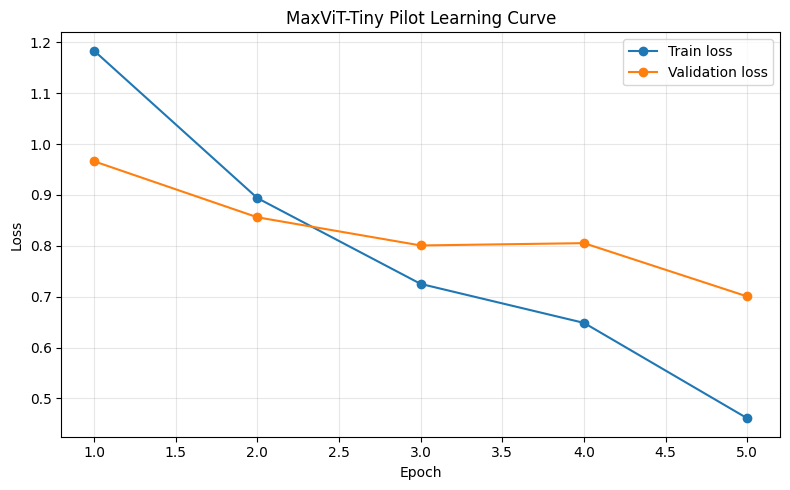

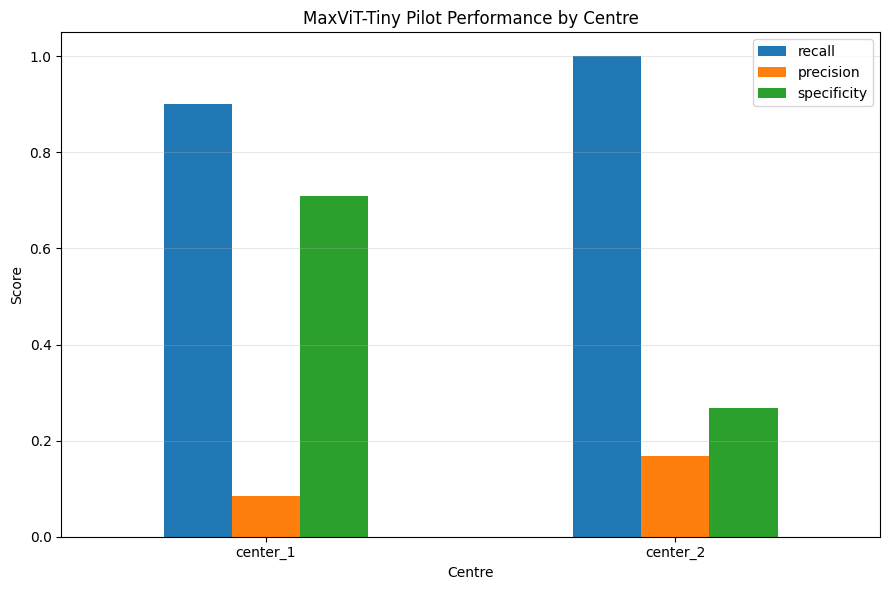

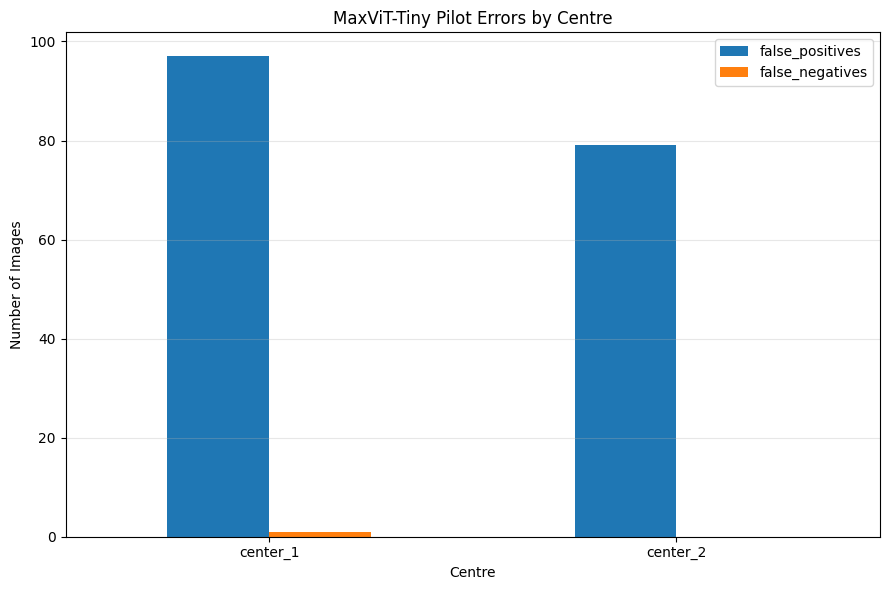


FINAL MAXVIT-TINY PILOT SUMMARY
Best epoch: 5
Selected threshold: 0.07366943359375

Overall test:
Recall: 0.9615
PPV: 0.1244
Specificity: 0.6018
AUROC: 0.9595
AUPRC: 0.8221
False positives: 176
False negatives: 1

Center 1:
Recall: 0.9
False positives: 97
False negatives: 1

Center 2:
Recall: 1.0
False positives: 79
False negatives: 0

Files saved:
/content/drive/MyDrive/RARE26 Phase2/models/maxvit_tiny_384_pilot_best.pth
/content/drive/MyDrive/RARE26 Phase2/models/maxvit_tiny_384_pilot_latest.pth
/content/drive/MyDrive/RARE26 Phase2/results/maxvit_tiny_384_pilot_history.csv
/content/drive/MyDrive/RARE26 Phase2/results/maxvit_tiny_384_pilot_validation_threshold_search.csv
/content/drive/MyDrive/RARE26 Phase2/results/maxvit_tiny_384_pilot_test_metrics.csv
/content/drive/MyDrive/RARE26 Phase2/results/maxvit_tiny_384_pilot_test_predictions.csv
/content/drive/MyDrive/RARE26 Phase2/figures/maxvit_tiny_384_pilot_learning_curve.png
/content/drive/MyDrive/RARE26 Phase2/figures/maxvit_tiny_384

In [ ]:
# ================================================================
# PHASE 2A — CELL 3
# MAXVIT-TINY 384 SINGLE-SPLIT PILOT TRAINING
#
# Input:
#   Phase 1 locked train/validation/test CSVs
#
# Output:
#   Phase 2 models/results/figures
#
# Model:
#   ImageNet-pretrained MaxViT-Tiny 384
#
# Training:
#   BCEWithLogitsLoss + pos_weight
#   AdamW
#   CosineAnnealingWarmRestarts
#   Mixed precision
#   Strong augmentation
#
# Selection:
#   Best model by validation AUPRC
#   Threshold selected on validation only
# ================================================================

!pip install -q --upgrade timm

import os
import time
import random
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import timm

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

from IPython.display import display as show_table


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if device.type != "cuda":
    raise RuntimeError(
        "GPU available nahi hai. MaxViT training ke liye T4 GPU zaroori hai."
    )

print("=" * 90)
print("PHASE 2A — MAXVIT-TINY PILOT TRAINING")
print("=" * 90)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# 2. PATHS
# ================================================================

phase1_folder = Path("/content/drive/MyDrive/RARE26")
phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

splits_folder = phase1_folder / "splits"

phase2_models_folder = phase2_folder / "models"
phase2_results_folder = phase2_folder / "results"
phase2_figures_folder = phase2_folder / "figures"

phase2_models_folder.mkdir(parents=True, exist_ok=True)
phase2_results_folder.mkdir(parents=True, exist_ok=True)
phase2_figures_folder.mkdir(parents=True, exist_ok=True)

train_csv_path = splits_folder / "train_colab.csv"
validation_csv_path = splits_folder / "validation_colab.csv"
test_csv_path = splits_folder / "test_colab.csv"

best_model_path = (
    phase2_models_folder
    / "maxvit_tiny_384_pilot_best.pth"
)

latest_model_path = (
    phase2_models_folder
    / "maxvit_tiny_384_pilot_latest.pth"
)

history_path = (
    phase2_results_folder
    / "maxvit_tiny_384_pilot_history.csv"
)

validation_threshold_search_path = (
    phase2_results_folder
    / "maxvit_tiny_384_pilot_validation_threshold_search.csv"
)

test_metrics_path = (
    phase2_results_folder
    / "maxvit_tiny_384_pilot_test_metrics.csv"
)

test_predictions_path = (
    phase2_results_folder
    / "maxvit_tiny_384_pilot_test_predictions.csv"
)

learning_curve_path = (
    phase2_figures_folder
    / "maxvit_tiny_384_pilot_learning_curve.png"
)

per_center_scores_path = (
    phase2_figures_folder
    / "maxvit_tiny_384_pilot_per_center_scores.png"
)

per_center_errors_path = (
    phase2_figures_folder
    / "maxvit_tiny_384_pilot_per_center_errors.png"
)


# ================================================================
# 3. TRAINING CONFIG
# ================================================================

MODEL_NAME = "maxvit_tiny_tf_384.in1k"
IMAGE_SIZE = 384

NUM_EPOCHS = 5

# T4 GPU ke liye safe pilot setting
BATCH_SIZE = 4

# Effective batch size = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
GRADIENT_ACCUMULATION_STEPS = 4

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 1e-4

NUM_WORKERS = 2

print("\nTraining config:")
print("Model:", MODEL_NAME)
print("Image size:", IMAGE_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Effective batch size:", BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Learning rate:", LEARNING_RATE)


# ================================================================
# 4. READ DATA
# ================================================================

train_df = pd.read_csv(train_csv_path)
validation_df = pd.read_csv(validation_csv_path)
test_df = pd.read_csv(test_csv_path)


def prepare_dataframe(dataframe):

    dataframe = dataframe.copy().reset_index(drop=True)

    dataframe["colab_path"] = (
        dataframe["colab_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    dataframe["label"] = dataframe["label"].astype(int)

    dataframe["center_name"] = (
        dataframe["center"]
        .astype(str)
        .str.lower()
        .str.replace("centre_", "center_", regex=False)
    )

    exists_mask = dataframe["colab_path"].apply(
        lambda image_path: Path(image_path).exists()
    )

    missing_count = int((~exists_mask).sum())

    if missing_count > 0:
        print(dataframe.loc[~exists_mask, "colab_path"].head())
        raise FileNotFoundError(
            "Images missing hain. Pehle Cell 1 setup dobara run karein."
        )

    return dataframe


train_df = prepare_dataframe(train_df)
validation_df = prepare_dataframe(validation_df)
test_df = prepare_dataframe(test_df)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))

print("\nTrain distribution:")
show_table(pd.crosstab(train_df["center_name"], train_df["label"]))

print("\nValidation distribution:")
show_table(pd.crosstab(validation_df["center_name"], validation_df["label"]))

print("\nTest distribution:")
show_table(pd.crosstab(test_df["center_name"], test_df["label"]))


# ================================================================
# 5. TRANSFORMS
# MaxViT timm config uses mean/std = 0.5
# ================================================================

train_transform = transforms.Compose([

    transforms.Resize((420, 420)),

    transforms.RandomResizedCrop(
        size=384,
        scale=(0.82, 1.00),
        ratio=(0.90, 1.10)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=12),

    transforms.ColorJitter(
        brightness=0.16,
        contrast=0.16,
        saturation=0.08,
        hue=0.02
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 0.8)
            )
        ],
        p=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),

    transforms.RandomErasing(
        p=0.15,
        scale=(0.01, 0.05),
        ratio=(0.5, 2.0),
        value=0
    ),
])


evaluation_transform = transforms.Compose([

    transforms.Resize((384, 384)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    ),
])


# ================================================================
# 6. DATASET CLASS
# ================================================================

class EndoscopyBinaryDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.copy().reset_index(drop=True)
        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = str(row["colab_path"])

        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = float(row["label"])

        center_name = str(row["center_name"])

        return image, torch.tensor(label, dtype=torch.float32), center_name


train_dataset = EndoscopyBinaryDataset(
    train_df,
    transform=train_transform
)

validation_dataset = EndoscopyBinaryDataset(
    validation_df,
    transform=evaluation_transform
)

test_dataset = EndoscopyBinaryDataset(
    test_df,
    transform=evaluation_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


print("\nBatches:")
print("Train batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))


# ================================================================
# 7. MODEL
# ================================================================

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=1
)

model = model.to(device)


# ================================================================
# 8. LOSS, OPTIMIZER, SCHEDULER
# ================================================================

normal_count = int((train_df["label"] == 0).sum())
positive_count = int((train_df["label"] == 1).sum())

pos_weight_value = normal_count / positive_count

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=3,
    T_mult=1,
    eta_min=1e-6
)

scaler = torch.cuda.amp.GradScaler()

print("\nClass counts:")
print("Normal:", normal_count)
print("Neoplasia:", positive_count)
print("pos_weight:", pos_weight_value)


# ================================================================
# 9. METRIC FUNCTIONS
# ================================================================

def calculate_metrics(labels, probabilities, threshold=0.5):

    labels = np.asarray(labels).astype(int)
    probabilities = np.asarray(probabilities).astype(float)

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    if len(np.unique(labels)) == 2:
        auroc = roc_auc_score(labels, probabilities)
        auprc = average_precision_score(labels, probabilities)
    else:
        auroc = np.nan
        auprc = np.nan

    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "specificity": float(specificity),
        "auroc": float(auroc),
        "auprc": float(auprc),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


def collect_predictions(model, data_loader, criterion=None):

    model.eval()

    labels_list = []
    probabilities_list = []
    centers_list = []

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for images, labels, center_names in data_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(images).squeeze(1)

                if criterion is not None:
                    loss = criterion(logits, labels)
                    total_loss += loss.item() * images.size(0)
                    total_samples += images.size(0)

            probabilities = torch.sigmoid(logits)

            labels_list.extend(labels.cpu().numpy())
            probabilities_list.extend(probabilities.cpu().numpy())
            centers_list.extend(list(center_names))

    average_loss = (
        total_loss / total_samples
        if criterion is not None and total_samples > 0
        else np.nan
    )

    return (
        np.array(labels_list),
        np.array(probabilities_list),
        np.array(centers_list),
        float(average_loss)
    )


# ================================================================
# 10. TRAINING LOOP
# ================================================================

best_validation_auprc = -1.0
history = []

print("\n" + "=" * 90)
print("MAXVIT-TINY PILOT TRAINING START")
print("=" * 90)

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start_time = time.time()

    model.train()

    running_loss = 0.0
    total_samples = 0
    correct_predictions = 0

    optimizer.zero_grad(set_to_none=True)

    for batch_index, (images, labels, _) in enumerate(train_loader, start=1):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)

            loss_for_backward = loss / GRADIENT_ACCUMULATION_STEPS

        scaler.scale(loss_for_backward).backward()

        if (
            batch_index % GRADIENT_ACCUMULATION_STEPS == 0
            or batch_index == len(train_loader)
        ):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).long()

        correct_predictions += (
            predictions == labels.long()
        ).sum().item()

    scheduler.step(epoch)

    train_loss = running_loss / total_samples
    train_accuracy = correct_predictions / total_samples

    (
        val_labels,
        val_probabilities,
        val_centers,
        val_loss
    ) = collect_predictions(
        model,
        validation_loader,
        criterion=criterion
    )

    val_metrics_default = calculate_metrics(
        labels=val_labels,
        probabilities=val_probabilities,
        threshold=0.5
    )

    epoch_seconds = time.time() - epoch_start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_metrics_default["accuracy"],
        "val_precision": val_metrics_default["precision"],
        "val_recall": val_metrics_default["recall"],
        "val_specificity": val_metrics_default["specificity"],
        "val_auroc": val_metrics_default["auroc"],
        "val_auprc": val_metrics_default["auprc"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "epoch_seconds": epoch_seconds,
    }

    history.append(epoch_record)

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    checkpoint_data = {
        "epoch": epoch,
        "model_name": MODEL_NAME,
        "image_size": IMAGE_SIZE,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "validation_metrics_default": val_metrics_default,
        "pos_weight": pos_weight_value,
        "training_config": {
            "num_epochs": NUM_EPOCHS,
            "batch_size": BATCH_SIZE,
            "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
        },
    }

    torch.save(checkpoint_data, latest_model_path)

    if val_metrics_default["auprc"] > best_validation_auprc:

        best_validation_auprc = val_metrics_default["auprc"]

        torch.save(checkpoint_data, best_model_path)

        best_message = " <-- Best model saved"

    else:
        best_message = ""

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Recall: {val_metrics_default['recall']:.4f} | "
        f"Val Precision: {val_metrics_default['precision']:.4f} | "
        f"Val AUROC: {val_metrics_default['auroc']:.4f} | "
        f"Val AUPRC: {val_metrics_default['auprc']:.4f} | "
        f"Time: {epoch_seconds:.1f}s"
        f"{best_message}"
    )


print("\nTraining complete.")
print("Best validation AUPRC:", best_validation_auprc)


# ================================================================
# 11. LOAD BEST MODEL
# ================================================================

best_checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

best_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=1
)

best_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

best_model = best_model.to(device)
best_model.eval()

print("\nBest checkpoint epoch:", best_checkpoint["epoch"])


# ================================================================
# 12. VALIDATION THRESHOLD SEARCH
# Conditions:
# - Overall validation recall >= 90%
# - Minimum per-centre validation recall >= 80%
# - Then maximum precision
# ================================================================

(
    validation_labels,
    validation_probabilities,
    validation_centers,
    _
) = collect_predictions(
    best_model,
    validation_loader,
    criterion=None
)

candidate_thresholds = np.unique(
    np.concatenate([
        np.array([0.0]),
        validation_probabilities,
        np.array([1.0]),
    ])
)

threshold_records = []

for threshold in candidate_thresholds:

    overall_metrics = calculate_metrics(
        validation_labels,
        validation_probabilities,
        threshold=threshold
    )

    center_1_mask = validation_centers == "center_1"
    center_2_mask = validation_centers == "center_2"

    c1_metrics = calculate_metrics(
        validation_labels[center_1_mask],
        validation_probabilities[center_1_mask],
        threshold=threshold
    )

    c2_metrics = calculate_metrics(
        validation_labels[center_2_mask],
        validation_probabilities[center_2_mask],
        threshold=threshold
    )

    minimum_center_recall = min(
        c1_metrics["recall"],
        c2_metrics["recall"]
    )

    threshold_records.append({
        "threshold": float(threshold),
        "overall_recall": overall_metrics["recall"],
        "overall_precision": overall_metrics["precision"],
        "overall_specificity": overall_metrics["specificity"],
        "center_1_recall": c1_metrics["recall"],
        "center_1_precision": c1_metrics["precision"],
        "center_2_recall": c2_metrics["recall"],
        "center_2_precision": c2_metrics["precision"],
        "minimum_center_recall": minimum_center_recall,
    })


threshold_search_df = pd.DataFrame(threshold_records)

eligible_df = threshold_search_df[
    (threshold_search_df["overall_recall"] >= 0.90)
    &
    (threshold_search_df["minimum_center_recall"] >= 0.80)
].copy()

if len(eligible_df) == 0:

    print("\nStrict centre-recall condition failed.")
    print("Using overall validation recall >=90% condition only.")

    eligible_df = threshold_search_df[
        threshold_search_df["overall_recall"] >= 0.90
    ].copy()

eligible_df = eligible_df.sort_values(
    by=[
        "overall_precision",
        "minimum_center_recall",
        "overall_specificity",
        "threshold",
    ],
    ascending=[
        False,
        False,
        False,
        False,
    ]
)

selected_threshold_row = eligible_df.iloc[0]

selected_threshold = float(
    selected_threshold_row["threshold"]
)

threshold_search_df.to_csv(
    validation_threshold_search_path,
    index=False
)

print("\n" + "=" * 90)
print("VALIDATION-SELECTED THRESHOLD")
print("=" * 90)

print("Selected threshold:", selected_threshold)
print("Validation overall recall:", selected_threshold_row["overall_recall"])
print("Validation overall precision:", selected_threshold_row["overall_precision"])
print("Validation Center 1 recall:", selected_threshold_row["center_1_recall"])
print("Validation Center 2 recall:", selected_threshold_row["center_2_recall"])


# ================================================================
# 13. TEST EVALUATION
# ================================================================

(
    test_labels,
    test_probabilities,
    test_centers,
    _
) = collect_predictions(
    best_model,
    test_loader,
    criterion=None
)

test_metric_rows = []

for evaluation_name, threshold in [
    ("default_threshold", 0.5),
    ("validation_selected_threshold", selected_threshold),
]:

    overall_metrics = calculate_metrics(
        test_labels,
        test_probabilities,
        threshold=threshold
    )

    test_metric_rows.append({
        "scope": "overall",
        "center": "all_centers",
        "evaluation": evaluation_name,
        "threshold": threshold,
        **overall_metrics,
    })

    for center_name in ["center_1", "center_2"]:

        center_mask = test_centers == center_name

        center_metrics = calculate_metrics(
            test_labels[center_mask],
            test_probabilities[center_mask],
            threshold=threshold
        )

        test_metric_rows.append({
            "scope": "per_center",
            "center": center_name,
            "evaluation": evaluation_name,
            "threshold": threshold,
            **center_metrics,
        })


test_metrics_df = pd.DataFrame(test_metric_rows)
test_metrics_df.to_csv(test_metrics_path, index=False)

print("\n" + "=" * 100)
print("MAXVIT-TINY PILOT TEST RESULTS")
print("=" * 100)

show_table(test_metrics_df)


# ================================================================
# 14. SAVE TEST PREDICTIONS
# ================================================================

test_predictions_df = test_df.copy().reset_index(drop=True)

test_predictions_df["true_label"] = test_labels
test_predictions_df["maxvit_probability"] = test_probabilities
test_predictions_df["selected_threshold"] = selected_threshold
test_predictions_df["maxvit_prediction"] = (
    test_probabilities >= selected_threshold
).astype(int)

test_predictions_df.to_csv(test_predictions_path, index=False)


# ================================================================
# 15. GRAPHS
# ================================================================

history_df = pd.read_csv(history_path)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MaxViT-Tiny Pilot Learning Curve")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(learning_curve_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


selected_test_df = test_metrics_df[
    test_metrics_df["evaluation"] == "validation_selected_threshold"
].copy()

per_center_df = selected_test_df[
    selected_test_df["scope"] == "per_center"
].copy()

per_center_df = per_center_df.set_index("center")

per_center_df[
    ["recall", "precision", "specificity"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("MaxViT-Tiny Pilot Performance by Centre")
plt.xlabel("Centre")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(per_center_scores_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


per_center_df[
    ["false_positives", "false_negatives"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("MaxViT-Tiny Pilot Errors by Centre")
plt.xlabel("Centre")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(per_center_errors_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ================================================================
# 16. FINAL SUMMARY
# ================================================================

selected_overall_row = selected_test_df[
    selected_test_df["scope"] == "overall"
].iloc[0]

selected_c1_row = selected_test_df[
    selected_test_df["center"] == "center_1"
].iloc[0]

selected_c2_row = selected_test_df[
    selected_test_df["center"] == "center_2"
].iloc[0]

print("\n" + "=" * 100)
print("FINAL MAXVIT-TINY PILOT SUMMARY")
print("=" * 100)

print("Best epoch:", best_checkpoint["epoch"])
print("Selected threshold:", selected_threshold)

print("\nOverall test:")
print("Recall:", round(selected_overall_row["recall"], 4))
print("PPV:", round(selected_overall_row["precision"], 4))
print("Specificity:", round(selected_overall_row["specificity"], 4))
print("AUROC:", round(selected_overall_row["auroc"], 4))
print("AUPRC:", round(selected_overall_row["auprc"], 4))
print("False positives:", int(selected_overall_row["false_positives"]))
print("False negatives:", int(selected_overall_row["false_negatives"]))

print("\nCenter 1:")
print("Recall:", round(selected_c1_row["recall"], 4))
print("False positives:", int(selected_c1_row["false_positives"]))
print("False negatives:", int(selected_c1_row["false_negatives"]))

print("\nCenter 2:")
print("Recall:", round(selected_c2_row["recall"], 4))
print("False positives:", int(selected_c2_row["false_positives"]))
print("False negatives:", int(selected_c2_row["false_negatives"]))

print("\nFiles saved:")
print(best_model_path)
print(latest_model_path)
print(history_path)
print(validation_threshold_search_path)
print(test_metrics_path)
print(test_predictions_path)
print(learning_curve_path)
print(per_center_scores_path)
print(per_center_errors_path)


gc.collect()
torch.cuda.empty_cache()

PHASE 2A — CELL 4 HYBRID ENSEMBLE SEARCH
Device: cuda
GPU: Tesla T4

Model path check:
Phase 1 baseline ResNet : True | /content/drive/MyDrive/RARE26/models/resnet18_baseline_best.pth
Phase 1 weighted augmentation ResNet : True | /content/drive/MyDrive/RARE26/models/resnet18_weighted_augmentation_best.pth
Phase 2 MaxViT pilot : True | /content/drive/MyDrive/RARE26 Phase2/models/maxvit_tiny_384_pilot_best.pth

Validation rows: 461
Test rows: 468

Models loaded successfully.

Generating validation predictions...
Generating test predictions...
Predictions generated.

VALIDATION WEIGHT SEARCH
Best validation weights:
Baseline weight: 0.9
Weighted-Aug weight: 0.05
MaxViT weight: 0.05
Selected threshold: 0.02751749224262312

Top 10 validation weight candidates:


,baseline_weight,weighted_aug_weight,maxvit_weight,selected_threshold,validation_recall,validation_precision,validation_specificity,validation_auroc,validation_auprc,validation_center_1_recall,validation_center_2_recall,minimum_center_recall
0,0.90,0.05,0.05,0.027517,0.956522,0.318841,0.892694,0.968136,0.793246,0.888889,1.0,0.888889
1,0.85,0.10,0.05,0.029849,0.956522,0.305556,0.885845,0.968037,0.792293,0.888889,1.0,0.888889
2,0.80,0.10,0.10,0.040591,0.956522,0.297297,0.881279,0.969724,0.792607,0.888889,1.0,0.888889
3,0.75,0.15,0.10,0.046326,0.956522,0.297297,0.881279,0.968831,0.790467,0.888889,1.0,0.888889
4,0.05,0.25,0.70,0.176379,0.956522,0.297297,0.881279,0.958408,0.775774,0.888889,1.0,0.888889
5,0.20,0.20,0.60,0.148020,0.956522,0.293333,0.878995,0.959400,0.781560,0.888889,1.0,0.888889
6,0.00,0.25,0.75,0.184561,0.956522,0.293333,0.878995,0.957812,0.771845,0.888889,1.0,0.888889
7,0.25,0.20,0.55,0.138813,0.956522,0.289474,0.876712,0.960294,0.781586,0.888889,1.0,0.888889
8,0.00,0.30,0.70,0.176351,0.956522,0.289474,0.876712,0.959797,0.771038,0.888889,1.0,0.888889
9,0.80,0.15,0.05,0.030467,0.956522,0.285714,0.874429,0.967540,0.792396,0.888889,1.0,0.888889



HYBRID ENSEMBLE TEST RESULTS


,scope,center,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,overall,all_centers,phase1_resnet_ensemble_0.45_0.55,0.016076,0.814103,0.225225,0.961538,0.805430,0.976592,0.902252,356,86,1,25
1,per_center,center_1,phase1_resnet_ensemble_0.45_0.55,0.016076,0.869186,0.169811,0.900000,0.868263,0.953293,0.681517,290,44,1,9
2,per_center,center_2,phase1_resnet_ensemble_0.45_0.55,0.016076,0.661290,0.275862,1.000000,0.611111,1.000000,1.000000,66,42,0,16
3,overall,all_centers,maxvit_only,0.073669,0.621795,0.124378,0.961538,0.601810,0.959363,0.822107,266,176,1,25
4,per_center,center_1,maxvit_only,0.073669,0.715116,0.084906,0.900000,0.709581,0.933683,0.646676,237,97,1,9
5,per_center,center_2,maxvit_only,0.073669,0.362903,0.168421,1.000000,0.268519,0.993345,0.960453,29,79,0,16
6,overall,all_centers,selected_hybrid_ensemble,0.027517,0.884615,0.320513,0.961538,0.880090,0.988775,0.915444,389,53,1,25
7,per_center,center_1,selected_hybrid_ensemble,0.027517,0.933140,0.290323,0.900000,0.934132,0.985629,0.787291,312,22,1,9
8,per_center,center_2,selected_hybrid_ensemble,0.027517,0.750000,0.340426,1.000000,0.712963,1.000000,1.000000,77,31,0,16



OVERALL COMPARISON SUMMARY


,evaluation,threshold,precision,recall,specificity,auroc,auprc,false_positives,false_negatives
0,phase1_resnet_ensemble_0.45_0.55,0.016076,0.225225,0.961538,0.80543,0.976592,0.902252,86,1
3,maxvit_only,0.073669,0.124378,0.961538,0.60181,0.959363,0.822107,176,1
6,selected_hybrid_ensemble,0.027517,0.320513,0.961538,0.88009,0.988775,0.915444,53,1


<Figure size 1000x600 with 0 Axes>

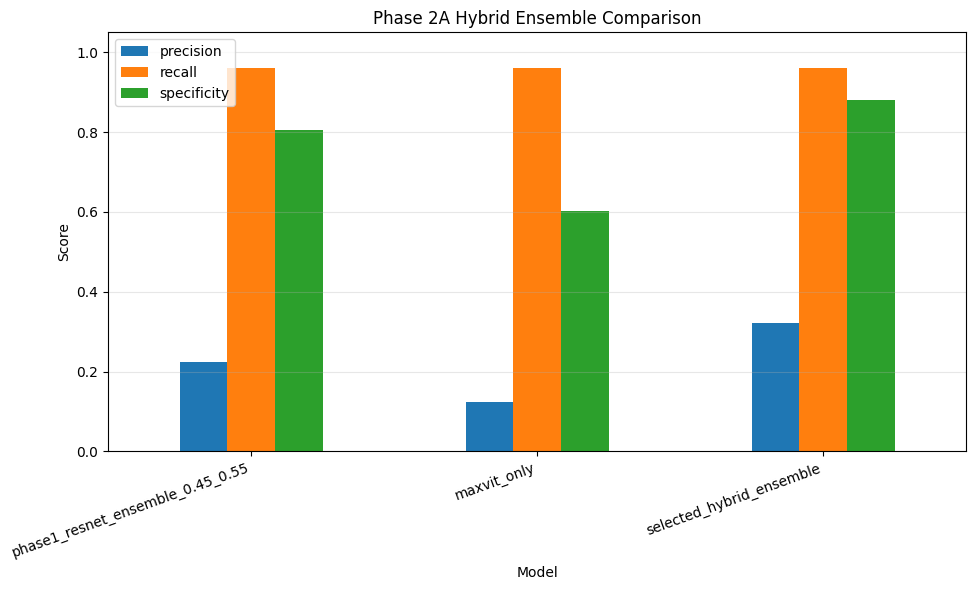


Files saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_validation_weight_search.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_summary.csv
/content/drive/MyDrive/RARE26 Phase2/figures/phase2a_hybrid_ensemble_comparison.png

FINAL SELECTED HYBRID:
Baseline weight: 0.9
Weighted-Aug weight: 0.05
MaxViT weight: 0.05
Threshold: 0.02751749224262312


In [ ]:
# ================================================================
# PHASE 2A — CELL 4
# HYBRID ENSEMBLE SEARCH:
# Phase 1 ResNet Baseline + Phase 1 Weighted-Aug + Phase 2 MaxViT
#
# Purpose:
# - No new training
# - Load saved models
# - Get validation/test probabilities
# - Search ensemble weights on validation only
# - Evaluate selected hybrid on held-out test
# ================================================================

!pip install -q --upgrade timm

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import timm
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

from IPython.display import display as show_table


# ================================================================
# 1. BASIC SETUP
# ================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type != "cuda":
    raise RuntimeError("GPU available nahi hai. Runtime > Change runtime type > T4 GPU select karein.")

print("=" * 90)
print("PHASE 2A — CELL 4 HYBRID ENSEMBLE SEARCH")
print("=" * 90)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# 2. PATHS
# ================================================================

phase1_folder = Path("/content/drive/MyDrive/RARE26")
phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

splits_folder = phase1_folder / "splits"

phase1_models_folder = phase1_folder / "models"
phase2_models_folder = phase2_folder / "models"

phase2_results_folder = phase2_folder / "results"
phase2_figures_folder = phase2_folder / "figures"

phase2_results_folder.mkdir(parents=True, exist_ok=True)
phase2_figures_folder.mkdir(parents=True, exist_ok=True)

train_csv_path = splits_folder / "train_colab.csv"
validation_csv_path = splits_folder / "validation_colab.csv"
test_csv_path = splits_folder / "test_colab.csv"

baseline_model_path = phase1_models_folder / "resnet18_baseline_best.pth"
weighted_aug_model_path = phase1_models_folder / "resnet18_weighted_augmentation_best.pth"
maxvit_model_path = phase2_models_folder / "maxvit_tiny_384_pilot_best.pth"

required_model_paths = {
    "Phase 1 baseline ResNet": baseline_model_path,
    "Phase 1 weighted augmentation ResNet": weighted_aug_model_path,
    "Phase 2 MaxViT pilot": maxvit_model_path,
}

print("\nModel path check:")
for name, path in required_model_paths.items():
    print(name, ":", path.exists(), "|", path)
    if not path.exists():
        raise FileNotFoundError(f"Missing model file: {name} | {path}")


hybrid_validation_search_path = phase2_results_folder / "phase2a_hybrid_ensemble_validation_weight_search.csv"
hybrid_test_metrics_path = phase2_results_folder / "phase2a_hybrid_ensemble_test_metrics.csv"
hybrid_test_predictions_path = phase2_results_folder / "phase2a_hybrid_ensemble_test_predictions.csv"
hybrid_summary_path = phase2_results_folder / "phase2a_hybrid_ensemble_summary.csv"
hybrid_barplot_path = phase2_figures_folder / "phase2a_hybrid_ensemble_comparison.png"


# ================================================================
# 3. LOAD DATAFRAMES
# ================================================================

validation_df = pd.read_csv(validation_csv_path)
test_df = pd.read_csv(test_csv_path)

def prepare_dataframe(dataframe):
    dataframe = dataframe.copy().reset_index(drop=True)

    dataframe["colab_path"] = (
        dataframe["colab_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    dataframe["label"] = dataframe["label"].astype(int)

    dataframe["center_name"] = (
        dataframe["center"]
        .astype(str)
        .str.lower()
        .str.replace("centre_", "center_", regex=False)
    )

    exists_mask = dataframe["colab_path"].apply(lambda x: Path(x).exists())
    missing_count = int((~exists_mask).sum())

    if missing_count > 0:
        print(dataframe.loc[~exists_mask, "colab_path"].head(10).to_string(index=False))
        raise FileNotFoundError("Images missing hain. Pehle Cell 1 setup dobara run karein.")

    return dataframe

validation_df = prepare_dataframe(validation_df)
test_df = prepare_dataframe(test_df)

print("\nValidation rows:", len(validation_df))
print("Test rows:", len(test_df))


# ================================================================
# 4. DATASETS AND TRANSFORMS
# ================================================================

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

maxvit_transform = transforms.Compose([
    transforms.Resize((384, 384)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])


class EndoscopyDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.copy().reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(str(row["colab_path"])).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        center_name = str(row["center_name"])
        image_path = str(row["colab_path"])

        return image, label, center_name, image_path


def make_loader(dataframe, transform, batch_size):
    dataset = EndoscopyDataset(dataframe, transform)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )
    return loader


validation_resnet_loader = make_loader(validation_df, resnet_transform, batch_size=32)
test_resnet_loader = make_loader(test_df, resnet_transform, batch_size=32)

validation_maxvit_loader = make_loader(validation_df, maxvit_transform, batch_size=8)
test_maxvit_loader = make_loader(test_df, maxvit_transform, batch_size=8)


# ================================================================
# 5. MODEL LOADING HELPERS
# ================================================================

def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        if "model_state_dict" in checkpoint:
            return checkpoint["model_state_dict"]
        if "state_dict" in checkpoint:
            return checkpoint["state_dict"]
    return checkpoint


def load_resnet18_checkpoint(checkpoint_path):
    model = torchvision.models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 2)

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    state_dict = extract_state_dict(checkpoint)

    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()

    return model


def load_maxvit_checkpoint(checkpoint_path):
    model = timm.create_model(
        "maxvit_tiny_tf_384.in1k",
        pretrained=False,
        num_classes=1
    )

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    state_dict = extract_state_dict(checkpoint)

    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()

    return model


baseline_model = load_resnet18_checkpoint(baseline_model_path)
weighted_aug_model = load_resnet18_checkpoint(weighted_aug_model_path)
maxvit_model = load_maxvit_checkpoint(maxvit_model_path)

print("\nModels loaded successfully.")


# ================================================================
# 6. PREDICTION FUNCTIONS
# ================================================================

def predict_resnet_probabilities(model, loader):
    model.eval()

    labels_list = []
    probabilities_list = []
    centers_list = []
    paths_list = []

    with torch.no_grad():
        for images, labels, centers, image_paths in loader:
            images = images.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                probabilities = torch.softmax(logits, dim=1)[:, 1]

            labels_list.extend(labels.numpy())
            probabilities_list.extend(probabilities.detach().cpu().numpy())
            centers_list.extend(list(centers))
            paths_list.extend(list(image_paths))

    return (
        np.array(labels_list).astype(int),
        np.array(probabilities_list).astype(float),
        np.array(centers_list),
        np.array(paths_list),
    )


def predict_maxvit_probabilities(model, loader):
    model.eval()

    labels_list = []
    probabilities_list = []
    centers_list = []
    paths_list = []

    with torch.no_grad():
        for images, labels, centers, image_paths in loader:
            images = images.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images).squeeze(1)
                probabilities = torch.sigmoid(logits)

            labels_list.extend(labels.numpy())
            probabilities_list.extend(probabilities.detach().cpu().numpy())
            centers_list.extend(list(centers))
            paths_list.extend(list(image_paths))

    return (
        np.array(labels_list).astype(int),
        np.array(probabilities_list).astype(float),
        np.array(centers_list),
        np.array(paths_list),
    )


print("\nGenerating validation predictions...")

val_labels, val_baseline_probs, val_centers, val_paths = predict_resnet_probabilities(
    baseline_model,
    validation_resnet_loader
)

_, val_weighted_aug_probs, _, _ = predict_resnet_probabilities(
    weighted_aug_model,
    validation_resnet_loader
)

_, val_maxvit_probs, _, _ = predict_maxvit_probabilities(
    maxvit_model,
    validation_maxvit_loader
)

print("Generating test predictions...")

test_labels, test_baseline_probs, test_centers, test_paths = predict_resnet_probabilities(
    baseline_model,
    test_resnet_loader
)

_, test_weighted_aug_probs, _, _ = predict_resnet_probabilities(
    weighted_aug_model,
    test_resnet_loader
)

_, test_maxvit_probs, _, _ = predict_maxvit_probabilities(
    maxvit_model,
    test_maxvit_loader
)

print("Predictions generated.")


# ================================================================
# 7. METRIC FUNCTIONS
# ================================================================

def calculate_metrics(labels, probabilities, threshold):
    labels = np.asarray(labels).astype(int)
    probabilities = np.asarray(probabilities).astype(float)

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    if len(np.unique(labels)) == 2:
        auroc = roc_auc_score(labels, probabilities)
        auprc = average_precision_score(labels, probabilities)
    else:
        auroc = np.nan
        auprc = np.nan

    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "specificity": float(specificity),
        "auroc": float(auroc),
        "auprc": float(auprc),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


def select_threshold_on_validation(labels, probabilities, centers):
    candidate_thresholds = np.unique(
        np.concatenate([
            np.array([0.0]),
            probabilities,
            np.array([1.0]),
        ])
    )

    records = []

    for threshold in candidate_thresholds:
        overall_metrics = calculate_metrics(labels, probabilities, threshold)

        center_recalls = {}
        center_precisions = {}

        for center_name in ["center_1", "center_2"]:
            mask = centers == center_name

            center_metrics = calculate_metrics(
                labels[mask],
                probabilities[mask],
                threshold
            )

            center_recalls[center_name] = center_metrics["recall"]
            center_precisions[center_name] = center_metrics["precision"]

        records.append({
            "threshold": float(threshold),
            "overall_recall": overall_metrics["recall"],
            "overall_precision": overall_metrics["precision"],
            "overall_specificity": overall_metrics["specificity"],
            "overall_auroc": overall_metrics["auroc"],
            "overall_auprc": overall_metrics["auprc"],
            "center_1_recall": center_recalls["center_1"],
            "center_2_recall": center_recalls["center_2"],
            "center_1_precision": center_precisions["center_1"],
            "center_2_precision": center_precisions["center_2"],
            "minimum_center_recall": min(center_recalls["center_1"], center_recalls["center_2"]),
        })

    threshold_df = pd.DataFrame(records)

    eligible_df = threshold_df[
        (threshold_df["overall_recall"] >= 0.90)
        &
        (threshold_df["minimum_center_recall"] >= 0.80)
    ].copy()

    if len(eligible_df) == 0:
        eligible_df = threshold_df[
            threshold_df["overall_recall"] >= 0.90
        ].copy()

    selected_row = eligible_df.sort_values(
        by=[
            "overall_precision",
            "minimum_center_recall",
            "overall_specificity",
            "threshold",
        ],
        ascending=[
            False,
            False,
            False,
            False,
        ]
    ).iloc[0]

    return float(selected_row["threshold"]), selected_row, threshold_df


# ================================================================
# 8. SEARCH ENSEMBLE WEIGHTS ON VALIDATION ONLY
# ================================================================

print("\n" + "=" * 90)
print("VALIDATION WEIGHT SEARCH")
print("=" * 90)

weight_records = []

# Step 0.05 gives 231 combinations
weight_values = np.round(np.arange(0.0, 1.0001, 0.05), 2)

for baseline_weight in weight_values:
    for weighted_aug_weight in weight_values:
        maxvit_weight = round(1.0 - baseline_weight - weighted_aug_weight, 2)

        if maxvit_weight < -1e-9:
            continue

        if maxvit_weight < 0:
            maxvit_weight = 0.0

        validation_ensemble_probs = (
            baseline_weight * val_baseline_probs
            +
            weighted_aug_weight * val_weighted_aug_probs
            +
            maxvit_weight * val_maxvit_probs
        )

        selected_threshold, selected_row, _ = select_threshold_on_validation(
            val_labels,
            validation_ensemble_probs,
            val_centers
        )

        weight_records.append({
            "baseline_weight": float(baseline_weight),
            "weighted_aug_weight": float(weighted_aug_weight),
            "maxvit_weight": float(maxvit_weight),
            "selected_threshold": selected_threshold,
            "validation_recall": float(selected_row["overall_recall"]),
            "validation_precision": float(selected_row["overall_precision"]),
            "validation_specificity": float(selected_row["overall_specificity"]),
            "validation_auroc": float(selected_row["overall_auroc"]),
            "validation_auprc": float(selected_row["overall_auprc"]),
            "validation_center_1_recall": float(selected_row["center_1_recall"]),
            "validation_center_2_recall": float(selected_row["center_2_recall"]),
            "minimum_center_recall": float(selected_row["minimum_center_recall"]),
        })


weight_search_df = pd.DataFrame(weight_records)

weight_search_df = weight_search_df.sort_values(
    by=[
        "validation_precision",
        "minimum_center_recall",
        "validation_specificity",
        "validation_auprc",
    ],
    ascending=[
        False,
        False,
        False,
        False,
    ]
).reset_index(drop=True)

weight_search_df.to_csv(hybrid_validation_search_path, index=False)

best_weight_row = weight_search_df.iloc[0]

best_baseline_weight = float(best_weight_row["baseline_weight"])
best_weighted_aug_weight = float(best_weight_row["weighted_aug_weight"])
best_maxvit_weight = float(best_weight_row["maxvit_weight"])
best_selected_threshold = float(best_weight_row["selected_threshold"])

print("Best validation weights:")
print("Baseline weight:", best_baseline_weight)
print("Weighted-Aug weight:", best_weighted_aug_weight)
print("MaxViT weight:", best_maxvit_weight)
print("Selected threshold:", best_selected_threshold)

print("\nTop 10 validation weight candidates:")
show_table(weight_search_df.head(10))


# ================================================================
# 9. EVALUATE SELECTED HYBRID ON TEST
# ================================================================

test_hybrid_probs = (
    best_baseline_weight * test_baseline_probs
    +
    best_weighted_aug_weight * test_weighted_aug_probs
    +
    best_maxvit_weight * test_maxvit_probs
)

test_metric_rows = []

for evaluation_name, probabilities, threshold in [
    (
        "phase1_resnet_ensemble_0.45_0.55",
        0.45 * test_baseline_probs + 0.55 * test_weighted_aug_probs,
        None,
    ),
    (
        "maxvit_only",
        test_maxvit_probs,
        None,
    ),
    (
        "selected_hybrid_ensemble",
        test_hybrid_probs,
        best_selected_threshold,
    ),
]:

    if threshold is None:
        validation_probs_for_candidate = None

        if evaluation_name == "phase1_resnet_ensemble_0.45_0.55":
            validation_probs_for_candidate = (
                0.45 * val_baseline_probs
                +
                0.55 * val_weighted_aug_probs
            )

        if evaluation_name == "maxvit_only":
            validation_probs_for_candidate = val_maxvit_probs

        threshold, _, _ = select_threshold_on_validation(
            val_labels,
            validation_probs_for_candidate,
            val_centers
        )

    overall_metrics = calculate_metrics(
        test_labels,
        probabilities,
        threshold
    )

    test_metric_rows.append({
        "scope": "overall",
        "center": "all_centers",
        "evaluation": evaluation_name,
        "threshold": threshold,
        **overall_metrics,
    })

    for center_name in ["center_1", "center_2"]:
        mask = test_centers == center_name

        center_metrics = calculate_metrics(
            test_labels[mask],
            probabilities[mask],
            threshold
        )

        test_metric_rows.append({
            "scope": "per_center",
            "center": center_name,
            "evaluation": evaluation_name,
            "threshold": threshold,
            **center_metrics,
        })


test_metrics_df = pd.DataFrame(test_metric_rows)
test_metrics_df.to_csv(hybrid_test_metrics_path, index=False)

print("\n" + "=" * 100)
print("HYBRID ENSEMBLE TEST RESULTS")
print("=" * 100)
show_table(test_metrics_df)


# ================================================================
# 10. SAVE TEST PREDICTIONS
# ================================================================

test_predictions_df = test_df.copy().reset_index(drop=True)

test_predictions_df["true_label"] = test_labels
test_predictions_df["center_name"] = test_centers
test_predictions_df["baseline_probability"] = test_baseline_probs
test_predictions_df["weighted_aug_probability"] = test_weighted_aug_probs
test_predictions_df["maxvit_probability"] = test_maxvit_probs
test_predictions_df["hybrid_probability"] = test_hybrid_probs
test_predictions_df["hybrid_threshold"] = best_selected_threshold
test_predictions_df["hybrid_prediction"] = (
    test_hybrid_probs >= best_selected_threshold
).astype(int)

test_predictions_df.to_csv(hybrid_test_predictions_path, index=False)


# ================================================================
# 11. SUMMARY AND FIGURE
# ================================================================

overall_df = test_metrics_df[
    test_metrics_df["scope"] == "overall"
].copy()

summary_df = overall_df[
    [
        "evaluation",
        "threshold",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "false_positives",
        "false_negatives",
    ]
].copy()

summary_df.to_csv(hybrid_summary_path, index=False)

print("\n" + "=" * 100)
print("OVERALL COMPARISON SUMMARY")
print("=" * 100)
show_table(summary_df)


plot_df = summary_df.set_index("evaluation")[["precision", "recall", "specificity"]]

plt.figure(figsize=(10, 6))
plot_df.plot(kind="bar", figsize=(10, 6))
plt.title("Phase 2A Hybrid Ensemble Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(hybrid_barplot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


print("\nFiles saved:")
print(hybrid_validation_search_path)
print(hybrid_test_metrics_path)
print(hybrid_test_predictions_path)
print(hybrid_summary_path)
print(hybrid_barplot_path)

print("\nFINAL SELECTED HYBRID:")
print("Baseline weight:", best_baseline_weight)
print("Weighted-Aug weight:", best_weighted_aug_weight)
print("MaxViT weight:", best_maxvit_weight)
print("Threshold:", best_selected_threshold)

gc.collect()
torch.cuda.empty_cache()

PHASE 2A — FINAL HYBRID ERROR AUDIT
Predictions file exists: True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv
Metrics file exists: True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv

Phase 1 ensemble threshold: 0.0160755420336499
Hybrid threshold: 0.0275174922426231

MODEL ERROR SUMMARY


,model,true_negatives,false_positives,false_negatives,true_positives,precision_ppv,recall,specificity
0,phase1_resnet_ensemble,356,86,1,25,0.225225,0.961538,0.80543
1,phase2a_selected_hybrid,389,53,1,25,0.320513,0.961538,0.88009



HYBRID IMPROVEMENT SUMMARY


,item,value
0,fixed_false_positives,38.000000
1,new_false_positives_created_by_hybrid,5.000000
2,remaining_hybrid_errors,54.000000
3,remaining_hybrid_false_negatives,1.000000
4,false_positive_reduction_count,33.000000
5,false_positive_reduction_percent,38.372093



PER-CENTRE ERROR REDUCTION


,center,phase1_false_positives,hybrid_false_positives,fp_reduction,phase1_false_negatives,hybrid_false_negatives
0,center_1,44,22,22,1,1
1,center_2,42,31,11,0,0


<Figure size 800x500 with 0 Axes>

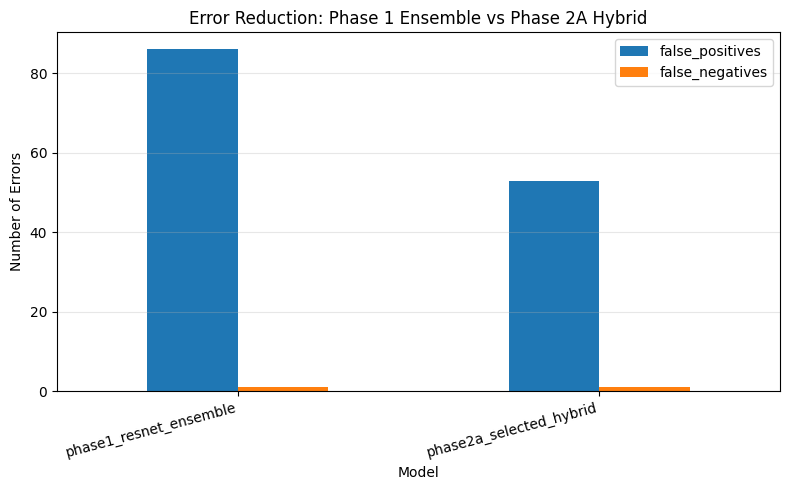


FINAL AUDIT CONCLUSION
Hybrid reduced false positives from 86 to 53
False positives reduced by: 33
Reduction percent: 38.37 %
Remaining hybrid false negatives: 1

Files saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_error_audit_cases.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_fixed_false_positives.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_remaining_errors.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_error_audit_summary.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_center_error_reduction.csv
/content/drive/MyDrive/RARE26 Phase2/figures/phase2a_hybrid_error_reduction.png


In [ ]:
# ================================================================
# PHASE 2A — CELL 5
# FINAL HYBRID ERROR AUDIT AND IMPROVEMENT ANALYSIS
#
# Purpose:
# - Compare Phase 1 ResNet ensemble vs Phase 2A selected hybrid
# - Identify fixed false positives
# - Identify remaining false negative
# - Save audit CSVs for thesis analysis
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import confusion_matrix


# ================================================================
# 1. PATHS
# ================================================================

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
results_folder = phase2_folder / "results"
figures_folder = phase2_folder / "figures"

hybrid_predictions_path = results_folder / "phase2a_hybrid_ensemble_test_predictions.csv"
hybrid_metrics_path = results_folder / "phase2a_hybrid_ensemble_test_metrics.csv"

audit_cases_path = results_folder / "phase2a_hybrid_error_audit_cases.csv"
fixed_fp_path = results_folder / "phase2a_hybrid_fixed_false_positives.csv"
remaining_error_path = results_folder / "phase2a_hybrid_remaining_errors.csv"
audit_summary_path = results_folder / "phase2a_hybrid_error_audit_summary.csv"

audit_figure_path = figures_folder / "phase2a_hybrid_error_reduction.png"

print("=" * 90)
print("PHASE 2A — FINAL HYBRID ERROR AUDIT")
print("=" * 90)

print("Predictions file exists:", hybrid_predictions_path.exists(), "|", hybrid_predictions_path)
print("Metrics file exists:", hybrid_metrics_path.exists(), "|", hybrid_metrics_path)

if not hybrid_predictions_path.exists():
    raise FileNotFoundError("Hybrid predictions file missing. Cell 4 dobara run karein.")

if not hybrid_metrics_path.exists():
    raise FileNotFoundError("Hybrid metrics file missing. Cell 4 dobara run karein.")


# ================================================================
# 2. LOAD FILES
# ================================================================

pred_df = pd.read_csv(hybrid_predictions_path)
metrics_df = pd.read_csv(hybrid_metrics_path)

# Phase 1 ensemble threshold from Cell 4 metrics
phase1_threshold = float(
    metrics_df[
        (metrics_df["evaluation"] == "phase1_resnet_ensemble_0.45_0.55")
        &
        (metrics_df["scope"] == "overall")
    ]["threshold"].iloc[0]
)

hybrid_threshold = float(
    metrics_df[
        (metrics_df["evaluation"] == "selected_hybrid_ensemble")
        &
        (metrics_df["scope"] == "overall")
    ]["threshold"].iloc[0]
)

print("\nPhase 1 ensemble threshold:", phase1_threshold)
print("Hybrid threshold:", hybrid_threshold)


# ================================================================
# 3. CREATE PHASE 1 AND HYBRID PREDICTIONS
# ================================================================

pred_df["phase1_ensemble_probability"] = (
    0.45 * pred_df["baseline_probability"]
    +
    0.55 * pred_df["weighted_aug_probability"]
)

pred_df["phase1_ensemble_prediction"] = (
    pred_df["phase1_ensemble_probability"] >= phase1_threshold
).astype(int)

pred_df["hybrid_prediction"] = (
    pred_df["hybrid_probability"] >= hybrid_threshold
).astype(int)

pred_df["phase1_error"] = (
    pred_df["phase1_ensemble_prediction"] != pred_df["true_label"]
).astype(int)

pred_df["hybrid_error"] = (
    pred_df["hybrid_prediction"] != pred_df["true_label"]
).astype(int)

pred_df["phase1_error_type"] = "correct"
pred_df.loc[
    (pred_df["true_label"] == 0) & (pred_df["phase1_ensemble_prediction"] == 1),
    "phase1_error_type"
] = "false_positive"
pred_df.loc[
    (pred_df["true_label"] == 1) & (pred_df["phase1_ensemble_prediction"] == 0),
    "phase1_error_type"
] = "false_negative"

pred_df["hybrid_error_type"] = "correct"
pred_df.loc[
    (pred_df["true_label"] == 0) & (pred_df["hybrid_prediction"] == 1),
    "hybrid_error_type"
] = "false_positive"
pred_df.loc[
    (pred_df["true_label"] == 1) & (pred_df["hybrid_prediction"] == 0),
    "hybrid_error_type"
] = "false_negative"


# ================================================================
# 4. IDENTIFY IMPROVEMENT CASES
# ================================================================

fixed_false_positives_df = pred_df[
    (pred_df["phase1_error_type"] == "false_positive")
    &
    (pred_df["hybrid_error_type"] == "correct")
].copy()

new_false_positives_df = pred_df[
    (pred_df["phase1_error_type"] == "correct")
    &
    (pred_df["hybrid_error_type"] == "false_positive")
].copy()

remaining_errors_df = pred_df[
    pred_df["hybrid_error"] == 1
].copy()

remaining_false_negative_df = pred_df[
    pred_df["hybrid_error_type"] == "false_negative"
].copy()


# ================================================================
# 5. SUMMARY COUNTS
# ================================================================

summary_rows = []

for model_name, prediction_column, error_type_column in [
    ("phase1_resnet_ensemble", "phase1_ensemble_prediction", "phase1_error_type"),
    ("phase2a_selected_hybrid", "hybrid_prediction", "hybrid_error_type"),
]:

    labels = pred_df["true_label"].astype(int).values
    predictions = pred_df[prediction_column].astype(int).values

    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    summary_rows.append({
        "model": model_name,
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
        "precision_ppv": precision,
        "recall": recall,
        "specificity": specificity,
    })

summary_df = pd.DataFrame(summary_rows)

phase1_fp = int(summary_df.loc[summary_df["model"] == "phase1_resnet_ensemble", "false_positives"].iloc[0])
hybrid_fp = int(summary_df.loc[summary_df["model"] == "phase2a_selected_hybrid", "false_positives"].iloc[0])

fp_reduction = phase1_fp - hybrid_fp
fp_reduction_percent = (fp_reduction / phase1_fp) * 100

extra_summary_df = pd.DataFrame([
    {
        "item": "fixed_false_positives",
        "value": len(fixed_false_positives_df),
    },
    {
        "item": "new_false_positives_created_by_hybrid",
        "value": len(new_false_positives_df),
    },
    {
        "item": "remaining_hybrid_errors",
        "value": len(remaining_errors_df),
    },
    {
        "item": "remaining_hybrid_false_negatives",
        "value": len(remaining_false_negative_df),
    },
    {
        "item": "false_positive_reduction_count",
        "value": fp_reduction,
    },
    {
        "item": "false_positive_reduction_percent",
        "value": fp_reduction_percent,
    },
])


# ================================================================
# 6. SAVE AUDIT FILES
# ================================================================

pred_df.to_csv(audit_cases_path, index=False)
fixed_false_positives_df.to_csv(fixed_fp_path, index=False)
remaining_errors_df.to_csv(remaining_error_path, index=False)

with open(audit_summary_path, "w", encoding="utf-8") as f:
    f.write("MODEL SUMMARY\n")
    summary_df.to_csv(f, index=False)

    f.write("\nEXTRA SUMMARY\n")
    extra_summary_df.to_csv(f, index=False)

print("\n" + "=" * 90)
print("MODEL ERROR SUMMARY")
print("=" * 90)
display(summary_df)

print("\n" + "=" * 90)
print("HYBRID IMPROVEMENT SUMMARY")
print("=" * 90)
display(extra_summary_df)


# ================================================================
# 7. PER-CENTRE ERROR REDUCTION
# ================================================================

center_summary_rows = []

for center_name in ["center_1", "center_2"]:

    center_df = pred_df[pred_df["center_name"] == center_name].copy()

    phase1_center_fp = int(
        (
            (center_df["true_label"] == 0)
            &
            (center_df["phase1_ensemble_prediction"] == 1)
        ).sum()
    )

    hybrid_center_fp = int(
        (
            (center_df["true_label"] == 0)
            &
            (center_df["hybrid_prediction"] == 1)
        ).sum()
    )

    phase1_center_fn = int(
        (
            (center_df["true_label"] == 1)
            &
            (center_df["phase1_ensemble_prediction"] == 0)
        ).sum()
    )

    hybrid_center_fn = int(
        (
            (center_df["true_label"] == 1)
            &
            (center_df["hybrid_prediction"] == 0)
        ).sum()
    )

    center_summary_rows.append({
        "center": center_name,
        "phase1_false_positives": phase1_center_fp,
        "hybrid_false_positives": hybrid_center_fp,
        "fp_reduction": phase1_center_fp - hybrid_center_fp,
        "phase1_false_negatives": phase1_center_fn,
        "hybrid_false_negatives": hybrid_center_fn,
    })

center_summary_df = pd.DataFrame(center_summary_rows)

center_summary_path = results_folder / "phase2a_hybrid_center_error_reduction.csv"
center_summary_df.to_csv(center_summary_path, index=False)

print("\n" + "=" * 90)
print("PER-CENTRE ERROR REDUCTION")
print("=" * 90)
display(center_summary_df)


# ================================================================
# 8. PLOT ERROR REDUCTION
# ================================================================

plot_df = summary_df.set_index("model")[["false_positives", "false_negatives"]]

plt.figure(figsize=(8, 5))
plot_df.plot(kind="bar", figsize=(8, 5))
plt.title("Error Reduction: Phase 1 Ensemble vs Phase 2A Hybrid")
plt.xlabel("Model")
plt.ylabel("Number of Errors")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(audit_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ================================================================
# 9. FINAL PRINT
# ================================================================

print("\n" + "=" * 90)
print("FINAL AUDIT CONCLUSION")
print("=" * 90)

print("Hybrid reduced false positives from", phase1_fp, "to", hybrid_fp)
print("False positives reduced by:", fp_reduction)
print("Reduction percent:", round(fp_reduction_percent, 2), "%")
print("Remaining hybrid false negatives:", len(remaining_false_negative_df))

print("\nFiles saved:")
print(audit_cases_path)
print(fixed_fp_path)
print(remaining_error_path)
print(audit_summary_path)
print(center_summary_path)
print(audit_figure_path)

PHASE 2A — FINAL CLEAN SUMMARY TABLE
Hybrid summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_summary.csv
Hybrid metrics : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv
Center error reduction : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_center_error_reduction.csv

Loaded files successfully.

FINAL CLEAN MODEL COMPARISON


,Model,Threshold,PPV / Precision,Recall / Sensitivity,Specificity,AUROC,AUPRC,False Positives,False Negatives
0,Phase 1 ResNet Ensemble,0.0161,0.2252,0.9615,0.8054,0.9766,0.9023,86,1
1,Phase 2A MaxViT-Tiny Only,0.0737,0.1244,0.9615,0.6018,0.9594,0.8221,176,1
2,Phase 2A Selected Hybrid,0.0275,0.3205,0.9615,0.8801,0.9888,0.9154,53,1



FINAL IMPROVEMENT SUMMARY


,Metric,Phase 1 Ensemble,Phase 2A Hybrid,Change,Interpretation
0,False Positives,86.0000,53.0000,-33.0000,33 fewer false positives
1,False Negatives,1.0000,1.0000,0.0000,same false negatives
2,Recall / Sensitivity,0.9615,0.9615,0.0000,recall maintained
3,PPV / Precision,0.2252,0.3205,0.0953,42.32% relative PPV improvement
4,Specificity,0.8054,0.8801,0.0747,specificity improved
5,AUROC,0.9766,0.9888,0.0122,ranking improved
6,AUPRC,0.9023,0.9154,0.0131,precision-recall ranking improved



FINAL PER-CENTRE ERROR REDUCTION


,Center,Phase 1 FP,Hybrid FP,FP Reduction,Phase 1 FN,Hybrid FN,FP Reduction Percent
0,center_1,44,22,22,1,1,50.00
1,center_2,42,31,11,0,0,26.19


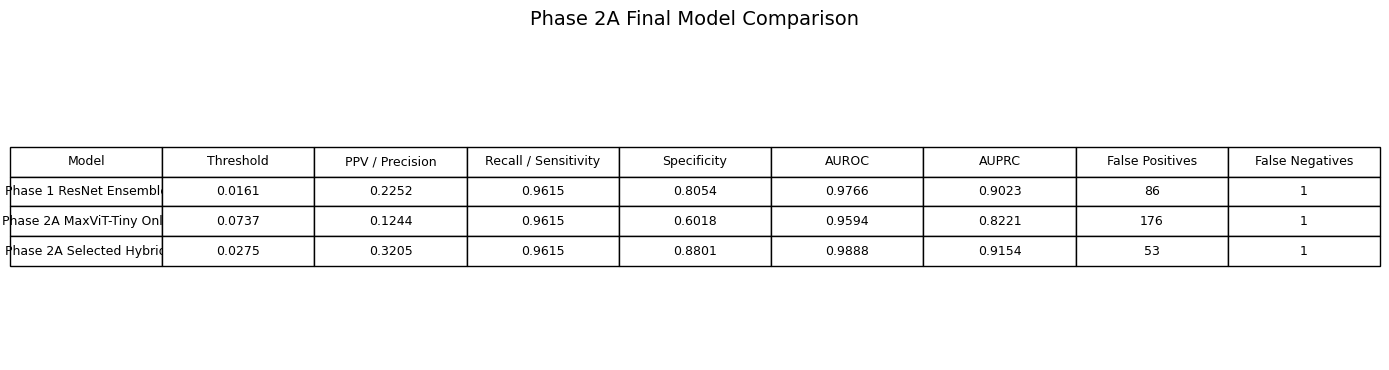

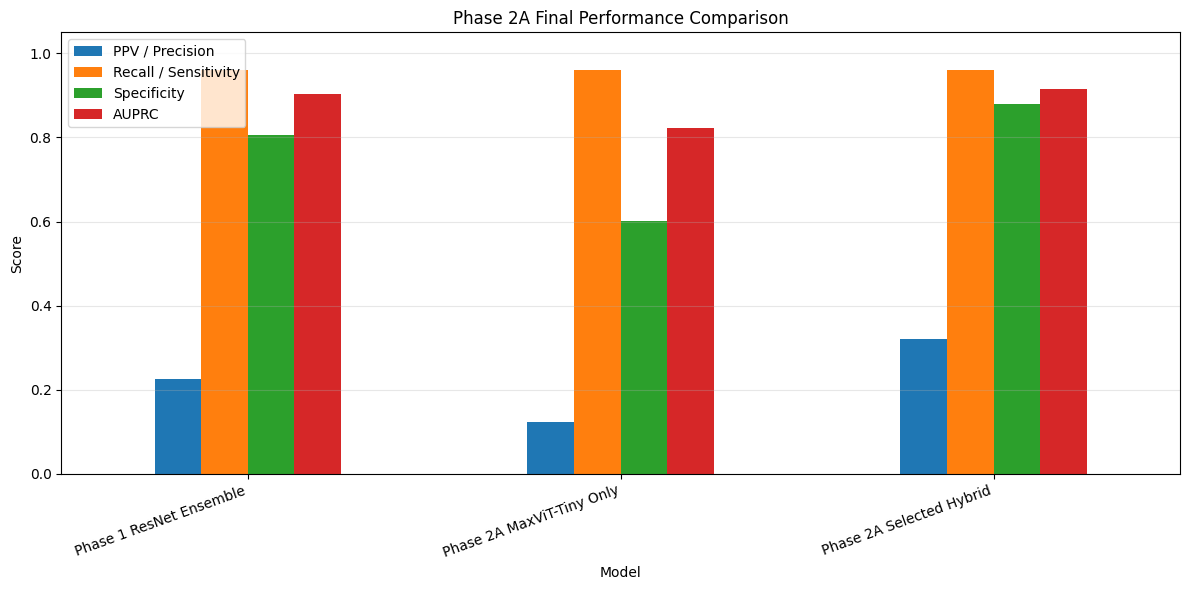


FINAL CONCLUSION PARAGRAPH
Phase 2A was completed using an ImageNet-pretrained MaxViT-Tiny 384 model and a validation-selected hybrid ensemble strategy. The standalone MaxViT-Tiny model achieved high recall but produced substantially more false positives than the Phase 1 ResNet ensemble. The best validation-selected hybrid ensemble assigned weights of 0.90 to the Phase 1 baseline ResNet-18, 0.05 to the weighted-augmentation ResNet-18, and 0.05 to the MaxViT-Tiny model, with a selected threshold of 0.0275. On the held-out test set, the hybrid ensemble maintained the same recall as the Phase 1 ensemble (0.9615) and the same number of false negatives (1), while reducing false positives from 86 to 53. This represents a false-positive reduction of 33 cases (38.37%). The PPV improved from 0.2252 to 0.3205, specificity improved from 0.8054 to 0.8801, AUROC improved from 0.9766 to 0.9888, and AUPRC improved from 0.9023 to 0.9154. Per-centre analysis also showed a reduction in false positives 

In [ ]:
# ================================================================
# PHASE 2A — CELL 6
# FINAL CLEAN SUMMARY TABLE FOR SUPERVISOR / THESIS
#
# Purpose:
# - Phase 1 Ensemble, MaxViT-only, and Phase 2A Hybrid comparison
# - Improvement summary
# - Per-centre error reduction summary
# - Save clean CSV + PNG + text conclusion
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from IPython.display import display as show_table


# ================================================================
# 1. PATHS
# ================================================================

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
results_folder = phase2_folder / "results"
figures_folder = phase2_folder / "figures"

hybrid_summary_path = results_folder / "phase2a_hybrid_ensemble_summary.csv"
hybrid_metrics_path = results_folder / "phase2a_hybrid_ensemble_test_metrics.csv"
center_error_path = results_folder / "phase2a_hybrid_center_error_reduction.csv"

final_summary_csv_path = results_folder / "phase2a_final_clean_summary_table.csv"
final_improvement_csv_path = results_folder / "phase2a_final_improvement_summary.csv"
final_center_csv_path = results_folder / "phase2a_final_per_center_summary.csv"

final_summary_figure_path = figures_folder / "phase2a_final_clean_summary_table.png"
final_comparison_figure_path = figures_folder / "phase2a_final_model_comparison_barplot.png"
final_conclusion_text_path = results_folder / "phase2a_final_conclusion_paragraph.txt"

print("=" * 90)
print("PHASE 2A — FINAL CLEAN SUMMARY TABLE")
print("=" * 90)

required_files = {
    "Hybrid summary": hybrid_summary_path,
    "Hybrid metrics": hybrid_metrics_path,
    "Center error reduction": center_error_path,
}

for name, path in required_files.items():
    print(name, ":", path.exists(), "|", path)
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {name} | {path}")


# ================================================================
# 2. LOAD RESULTS
# ================================================================

summary_df = pd.read_csv(hybrid_summary_path)
metrics_df = pd.read_csv(hybrid_metrics_path)
center_df = pd.read_csv(center_error_path)

print("\nLoaded files successfully.")


# ================================================================
# 3. CLEAN MODEL NAMES
# ================================================================

model_name_map = {
    "phase1_resnet_ensemble_0.45_0.55": "Phase 1 ResNet Ensemble",
    "maxvit_only": "Phase 2A MaxViT-Tiny Only",
    "selected_hybrid_ensemble": "Phase 2A Selected Hybrid",
}

summary_df["model"] = summary_df["evaluation"].map(model_name_map)

clean_summary_df = summary_df[
    [
        "model",
        "threshold",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "false_positives",
        "false_negatives",
    ]
].copy()

clean_summary_df = clean_summary_df.rename(columns={
    "model": "Model",
    "threshold": "Threshold",
    "precision": "PPV / Precision",
    "recall": "Recall / Sensitivity",
    "specificity": "Specificity",
    "auroc": "AUROC",
    "auprc": "AUPRC",
    "false_positives": "False Positives",
    "false_negatives": "False Negatives",
})

clean_summary_df = clean_summary_df[
    clean_summary_df["Model"].notna()
].copy()

# Round numeric columns
round_columns = [
    "Threshold",
    "PPV / Precision",
    "Recall / Sensitivity",
    "Specificity",
    "AUROC",
    "AUPRC",
]

for column in round_columns:
    clean_summary_df[column] = clean_summary_df[column].astype(float).round(4)

clean_summary_df["False Positives"] = clean_summary_df["False Positives"].astype(int)
clean_summary_df["False Negatives"] = clean_summary_df["False Negatives"].astype(int)

clean_summary_df.to_csv(final_summary_csv_path, index=False)

print("\n" + "=" * 90)
print("FINAL CLEAN MODEL COMPARISON")
print("=" * 90)

show_table(clean_summary_df)


# ================================================================
# 4. IMPROVEMENT SUMMARY
# ================================================================

phase1_row = clean_summary_df[
    clean_summary_df["Model"] == "Phase 1 ResNet Ensemble"
].iloc[0]

hybrid_row = clean_summary_df[
    clean_summary_df["Model"] == "Phase 2A Selected Hybrid"
].iloc[0]

fp_before = int(phase1_row["False Positives"])
fp_after = int(hybrid_row["False Positives"])
fn_before = int(phase1_row["False Negatives"])
fn_after = int(hybrid_row["False Negatives"])

fp_reduction = fp_before - fp_after
fp_reduction_percent = (fp_reduction / fp_before) * 100

ppv_before = float(phase1_row["PPV / Precision"])
ppv_after = float(hybrid_row["PPV / Precision"])
ppv_absolute_gain = ppv_after - ppv_before
ppv_relative_gain_percent = (ppv_absolute_gain / ppv_before) * 100

specificity_before = float(phase1_row["Specificity"])
specificity_after = float(hybrid_row["Specificity"])
specificity_gain = specificity_after - specificity_before

recall_before = float(phase1_row["Recall / Sensitivity"])
recall_after = float(hybrid_row["Recall / Sensitivity"])
recall_change = recall_after - recall_before

auprc_before = float(phase1_row["AUPRC"])
auprc_after = float(hybrid_row["AUPRC"])
auprc_gain = auprc_after - auprc_before

auroc_before = float(phase1_row["AUROC"])
auroc_after = float(hybrid_row["AUROC"])
auroc_gain = auroc_after - auroc_before

improvement_df = pd.DataFrame([
    {
        "Metric": "False Positives",
        "Phase 1 Ensemble": fp_before,
        "Phase 2A Hybrid": fp_after,
        "Change": -fp_reduction,
        "Interpretation": f"{fp_reduction} fewer false positives",
    },
    {
        "Metric": "False Negatives",
        "Phase 1 Ensemble": fn_before,
        "Phase 2A Hybrid": fn_after,
        "Change": fn_after - fn_before,
        "Interpretation": "same false negatives",
    },
    {
        "Metric": "Recall / Sensitivity",
        "Phase 1 Ensemble": recall_before,
        "Phase 2A Hybrid": recall_after,
        "Change": round(recall_change, 4),
        "Interpretation": "recall maintained",
    },
    {
        "Metric": "PPV / Precision",
        "Phase 1 Ensemble": ppv_before,
        "Phase 2A Hybrid": ppv_after,
        "Change": round(ppv_absolute_gain, 4),
        "Interpretation": f"{round(ppv_relative_gain_percent, 2)}% relative PPV improvement",
    },
    {
        "Metric": "Specificity",
        "Phase 1 Ensemble": specificity_before,
        "Phase 2A Hybrid": specificity_after,
        "Change": round(specificity_gain, 4),
        "Interpretation": "specificity improved",
    },
    {
        "Metric": "AUROC",
        "Phase 1 Ensemble": auroc_before,
        "Phase 2A Hybrid": auroc_after,
        "Change": round(auroc_gain, 4),
        "Interpretation": "ranking improved",
    },
    {
        "Metric": "AUPRC",
        "Phase 1 Ensemble": auprc_before,
        "Phase 2A Hybrid": auprc_after,
        "Change": round(auprc_gain, 4),
        "Interpretation": "precision-recall ranking improved",
    },
])

improvement_df.to_csv(final_improvement_csv_path, index=False)

print("\n" + "=" * 90)
print("FINAL IMPROVEMENT SUMMARY")
print("=" * 90)

show_table(improvement_df)


# ================================================================
# 5. PER-CENTRE SUMMARY
# ================================================================

center_clean_df = center_df.copy()

center_clean_df = center_clean_df.rename(columns={
    "center": "Center",
    "phase1_false_positives": "Phase 1 FP",
    "hybrid_false_positives": "Hybrid FP",
    "fp_reduction": "FP Reduction",
    "phase1_false_negatives": "Phase 1 FN",
    "hybrid_false_negatives": "Hybrid FN",
})

center_clean_df["FP Reduction Percent"] = (
    center_clean_df["FP Reduction"]
    /
    center_clean_df["Phase 1 FP"]
    *
    100
).round(2)

center_clean_df.to_csv(final_center_csv_path, index=False)

print("\n" + "=" * 90)
print("FINAL PER-CENTRE ERROR REDUCTION")
print("=" * 90)

show_table(center_clean_df)


# ================================================================
# 6. SAVE CLEAN TABLE AS PNG
# ================================================================

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.axis("off")

table = ax.table(
    cellText=clean_summary_df.values,
    colLabels=clean_summary_df.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.7)

plt.title(
    "Phase 2A Final Model Comparison",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.savefig(final_summary_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ================================================================
# 7. SAVE BARPLOT
# ================================================================

plot_df = clean_summary_df.set_index("Model")[
    [
        "PPV / Precision",
        "Recall / Sensitivity",
        "Specificity",
        "AUPRC",
    ]
]

plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Phase 2A Final Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(final_comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ================================================================
# 8. SAVE FINAL CONCLUSION PARAGRAPH
# ================================================================

conclusion_paragraph = f"""
Phase 2A was completed using an ImageNet-pretrained MaxViT-Tiny 384 model and a validation-selected hybrid ensemble strategy. The standalone MaxViT-Tiny model achieved high recall but produced substantially more false positives than the Phase 1 ResNet ensemble. The best validation-selected hybrid ensemble assigned weights of 0.90 to the Phase 1 baseline ResNet-18, 0.05 to the weighted-augmentation ResNet-18, and 0.05 to the MaxViT-Tiny model, with a selected threshold of {hybrid_row["Threshold"]}. On the held-out test set, the hybrid ensemble maintained the same recall as the Phase 1 ensemble ({recall_after:.4f}) and the same number of false negatives ({fn_after}), while reducing false positives from {fp_before} to {fp_after}. This represents a false-positive reduction of {fp_reduction} cases ({fp_reduction_percent:.2f}%). The PPV improved from {ppv_before:.4f} to {ppv_after:.4f}, specificity improved from {specificity_before:.4f} to {specificity_after:.4f}, AUROC improved from {auroc_before:.4f} to {auroc_after:.4f}, and AUPRC improved from {auprc_before:.4f} to {auprc_after:.4f}. Per-centre analysis also showed a reduction in false positives in both centres, indicating that the hybrid model improved precision and specificity without compromising sensitivity.
""".strip()

with open(final_conclusion_text_path, "w", encoding="utf-8") as file:
    file.write(conclusion_paragraph)

print("\n" + "=" * 90)
print("FINAL CONCLUSION PARAGRAPH")
print("=" * 90)
print(conclusion_paragraph)


# ================================================================
# 9. FINAL SAVED FILES
# ================================================================

print("\n" + "=" * 90)
print("FILES SAVED")
print("=" * 90)

print(final_summary_csv_path)
print(final_improvement_csv_path)
print(final_center_csv_path)
print(final_summary_figure_path)
print(final_comparison_figure_path)
print(final_conclusion_text_path)

print("\nSTATUS: PHASE 2A FINAL SUMMARY IS READY.")

In [ ]:
# ================================================================
# PHASE 2B — CELL 7
# SETUP FOLDERS AND VERIFY PHASE 2A FINAL FILES
#
# Purpose:
# - Same RARE26 Phase2 folder use karna
# - Phase2B ke results/figures/models subfolders banana
# - Phase2A final hybrid files verify karna
# ================================================================

import pandas as pd
from pathlib import Path

print("=" * 90)
print("PHASE 2B — SETUP")
print("=" * 90)

# Main folders
phase1_folder = Path("/content/drive/MyDrive/RARE26")
phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

# Phase 2A existing folders
phase2_results_folder = phase2_folder / "results"
phase2_figures_folder = phase2_folder / "figures"
phase2_models_folder = phase2_folder / "models"
phase2_notebooks_folder = phase2_folder / "notebooks"

# New Phase 2B subfolders
phase2b_results_folder = phase2_results_folder / "phase2b"
phase2b_figures_folder = phase2_figures_folder / "phase2b"
phase2b_models_folder = phase2_models_folder / "phase2b"

phase2b_results_folder.mkdir(parents=True, exist_ok=True)
phase2b_figures_folder.mkdir(parents=True, exist_ok=True)
phase2b_models_folder.mkdir(parents=True, exist_ok=True)

print("Phase 1 folder:", phase1_folder)
print("Phase 2 main folder:", phase2_folder)

print("\nPhase 2B folders created:")
print("Results:", phase2b_results_folder)
print("Figures:", phase2b_figures_folder)
print("Models:", phase2b_models_folder)

# Required Phase 2A files
required_files = {
    "Phase2A hybrid test metrics": phase2_results_folder / "phase2a_hybrid_ensemble_test_metrics.csv",
    "Phase2A hybrid test predictions": phase2_results_folder / "phase2a_hybrid_ensemble_test_predictions.csv",
    "Phase2A final clean summary": phase2_results_folder / "phase2a_final_clean_summary_table.csv",
    "Phase2A final improvement summary": phase2_results_folder / "phase2a_final_improvement_summary.csv",
    "Phase2A per-centre summary": phase2_results_folder / "phase2a_final_per_center_summary.csv",
    "Phase2A conclusion paragraph": phase2_results_folder / "phase2a_final_conclusion_paragraph.txt",
}

print("\n" + "=" * 90)
print("PHASE 2A REQUIRED FILE CHECK")
print("=" * 90)

missing_files = []

for name, path in required_files.items():
    exists = path.exists()
    print(name, ":", exists, "|", path)

    if not exists:
        missing_files.append(name)

if len(missing_files) > 0:
    raise FileNotFoundError(
        "Missing required Phase 2A files: " + ", ".join(missing_files)
    )

# Load key Phase2A summary
clean_summary_df = pd.read_csv(required_files["Phase2A final clean summary"])
hybrid_metrics_df = pd.read_csv(required_files["Phase2A hybrid test metrics"])
hybrid_predictions_df = pd.read_csv(required_files["Phase2A hybrid test predictions"])

print("\n" + "=" * 90)
print("PHASE 2A FINAL SUMMARY LOADED")
print("=" * 90)

display(clean_summary_df)

# Extract selected hybrid row
selected_hybrid_row = clean_summary_df[
    clean_summary_df["Model"] == "Phase 2A Selected Hybrid"
].iloc[0]

phase2b_setup_summary = pd.DataFrame([
    {
        "phase": "Phase 2B",
        "purpose": "robustness_and_statistical_reliability_analysis",
        "input_model": "Phase 2A Selected Hybrid Ensemble",
        "input_threshold": selected_hybrid_row["Threshold"],
        "test_recall": selected_hybrid_row["Recall / Sensitivity"],
        "test_ppv": selected_hybrid_row["PPV / Precision"],
        "test_specificity": selected_hybrid_row["Specificity"],
        "test_auroc": selected_hybrid_row["AUROC"],
        "test_auprc": selected_hybrid_row["AUPRC"],
        "false_positives": selected_hybrid_row["False Positives"],
        "false_negatives": selected_hybrid_row["False Negatives"],
        "phase2b_results_folder": str(phase2b_results_folder),
        "phase2b_figures_folder": str(phase2b_figures_folder),
        "status": "READY_FOR_PHASE2B_ANALYSIS",
    }
])

phase2b_setup_path = phase2b_results_folder / "phase2b_setup_summary.csv"
phase2b_setup_summary.to_csv(phase2b_setup_path, index=False)

print("\n" + "=" * 90)
print("PHASE 2B SETUP SUMMARY")
print("=" * 90)

display(phase2b_setup_summary)

print("\nSaved:")
print(phase2b_setup_path)

print("\nSTATUS: PHASE 2B SETUP IS READY.")

PHASE 2B — SETUP
Phase 1 folder: /content/drive/MyDrive/RARE26
Phase 2 main folder: /content/drive/MyDrive/RARE26 Phase2

Phase 2B folders created:
Results: /content/drive/MyDrive/RARE26 Phase2/results/phase2b
Figures: /content/drive/MyDrive/RARE26 Phase2/figures/phase2b
Models: /content/drive/MyDrive/RARE26 Phase2/models/phase2b

PHASE 2A REQUIRED FILE CHECK
Phase2A hybrid test metrics : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv
Phase2A hybrid test predictions : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv
Phase2A final clean summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_clean_summary_table.csv
Phase2A final improvement summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_improvement_summary.csv
Phase2A per-centre summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_per_center_summary.csv
Phase2A conclusion p

,Model,Threshold,PPV / Precision,Recall / Sensitivity,Specificity,AUROC,AUPRC,False Positives,False Negatives
0,Phase 1 ResNet Ensemble,0.0161,0.2252,0.9615,0.8054,0.9766,0.9023,86,1
1,Phase 2A MaxViT-Tiny Only,0.0737,0.1244,0.9615,0.6018,0.9594,0.8221,176,1
2,Phase 2A Selected Hybrid,0.0275,0.3205,0.9615,0.8801,0.9888,0.9154,53,1



PHASE 2B SETUP SUMMARY


,phase,purpose,input_model,input_threshold,test_recall,test_ppv,test_specificity,test_auroc,test_auprc,false_positives,false_negatives,phase2b_results_folder,phase2b_figures_folder,status
0,Phase 2B,robustness_and_statistical_reliability_analysis,Phase 2A Selected Hybrid Ensemble,0.0275,0.9615,0.3205,0.8801,0.9888,0.9154,53,1,/content/drive/MyDrive/RARE26 Phase2/results/p...,/content/drive/MyDrive/RARE26 Phase2/figures/p...,READY_FOR_PHASE2B_ANALYSIS



Saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_setup_summary.csv

STATUS: PHASE 2B SETUP IS READY.


In [ ]:
import pandas as pd
from pathlib import Path

phase2 = Path("/content/drive/MyDrive/RARE26 Phase2")
results = phase2 / "results"
phase2b = results / "phase2b"

phase2b.mkdir(parents=True, exist_ok=True)

pred_path = results / "phase2a_hybrid_ensemble_test_predictions.csv"
metrics_path = results / "phase2a_hybrid_ensemble_test_metrics.csv"

print("Predictions:", pred_path.exists(), pred_path)
print("Metrics:", metrics_path.exists(), metrics_path)

pred_df = pd.read_csv(pred_path)
metrics_df = pd.read_csv(metrics_path)

print("Predictions shape:", pred_df.shape)
print("Metrics shape:", metrics_df.shape)

display(pred_df.head())
display(metrics_df.head())

print("STATUS: PHASE 2B FILES LOADED")

Predictions: True /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv
Metrics: True /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv
Predictions shape: (468, 17)
Metrics shape: (9, 14)


,file_path,relative_path,center,class,label,sha256,split,colab_path,file_exists,center_name,true_label,baseline_probability,weighted_aug_probability,maxvit_probability,hybrid_probability,hybrid_threshold,hybrid_prediction
0,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/9635e2134837435e94958803a02cebf6...,center_1,ndbe,0,8ef87f8004f82fda4d35557fab5531fe41c3aa227e029a...,test,/content/RARE26_data/center_1/ndbe/9635e213483...,True,center_1,0,0.000664,0.000936,0.030380,0.002164,0.027517,0
1,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/f896c1e5a7fe45b098ef8f1429180848...,center_1,ndbe,0,1278742718f3cb9c5a8bdd7487ada0e57a97c3f972b79d...,test,/content/RARE26_data/center_1/ndbe/f896c1e5a7f...,True,center_1,0,0.002839,0.003497,0.067688,0.006115,0.027517,0
2,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/0239a5b829f94786a840e0ad9f9dc4ed...,center_1,ndbe,0,fa840c97c580113c15cebd871090212935b1c5854d255b...,test,/content/RARE26_data/center_1/ndbe/0239a5b829f...,True,center_1,0,0.002132,0.000014,0.015488,0.002694,0.027517,0
3,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/121510b15f004dfd8556c5872b04979b...,center_1,ndbe,0,780a7e28900c9a1d98f579f52c918521f92f851a31852d...,test,/content/RARE26_data/center_1/ndbe/121510b15f0...,True,center_1,0,0.001138,0.000793,0.030853,0.002607,0.027517,0
4,C:\thesis\dataset\RARE25-train-data\center_1\n...,center_1/ndbe/b1ed79fc662c462d9923b59e7328b864...,center_1,ndbe,0,58b0b63ef08f4fb856006bf8833c7fbb0eb328f159f2de...,test,/content/RARE26_data/center_1/ndbe/b1ed79fc662...,True,center_1,0,0.002907,0.008495,0.061646,0.006123,0.027517,0


,scope,center,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,overall,all_centers,phase1_resnet_ensemble_0.45_0.55,0.016076,0.814103,0.225225,0.961538,0.805430,0.976592,0.902252,356,86,1,25
1,per_center,center_1,phase1_resnet_ensemble_0.45_0.55,0.016076,0.869186,0.169811,0.900000,0.868263,0.953293,0.681517,290,44,1,9
2,per_center,center_2,phase1_resnet_ensemble_0.45_0.55,0.016076,0.661290,0.275862,1.000000,0.611111,1.000000,1.000000,66,42,0,16
3,overall,all_centers,maxvit_only,0.073669,0.621795,0.124378,0.961538,0.601810,0.959363,0.822107,266,176,1,25
4,per_center,center_1,maxvit_only,0.073669,0.715116,0.084906,0.900000,0.709581,0.933683,0.646676,237,97,1,9


STATUS: PHASE 2B FILES LOADED


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Phase 1 ensemble probability
pred_df["phase1_probability"] = (
    0.45 * pred_df["baseline_probability"]
    +
    0.55 * pred_df["weighted_aug_probability"]
)

# Thresholds from metrics file
phase1_threshold = float(
    metrics_df[
        (metrics_df["evaluation"] == "phase1_resnet_ensemble_0.45_0.55")
        &
        (metrics_df["scope"] == "overall")
    ]["threshold"].iloc[0]
)

hybrid_threshold = float(
    metrics_df[
        (metrics_df["evaluation"] == "selected_hybrid_ensemble")
        &
        (metrics_df["scope"] == "overall")
    ]["threshold"].iloc[0]
)

def get_metrics(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "PPV": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "AUROC": roc_auc_score(y_true, y_prob),
        "AUPRC": average_precision_score(y_true, y_prob),
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "TN": tn
    }

y_true = pred_df["true_label"].astype(int).values

phase1_metrics = get_metrics(
    y_true,
    pred_df["phase1_probability"].values,
    phase1_threshold
)

hybrid_metrics = get_metrics(
    y_true,
    pred_df["hybrid_probability"].values,
    hybrid_threshold
)

original_compare_df = pd.DataFrame([
    {"Model": "Phase 1 ResNet Ensemble", **phase1_metrics},
    {"Model": "Phase 2A Selected Hybrid", **hybrid_metrics}
])

display(original_compare_df)

print("Phase 1 threshold:", phase1_threshold)
print("Hybrid threshold:", hybrid_threshold)
print("STATUS: PHASE 2B CELL 8B READY")

,Model,PPV,Recall,Specificity,AUROC,AUPRC,FP,FN,TP,TN
0,Phase 1 ResNet Ensemble,0.225225,0.961538,0.80543,0.976592,0.902252,86,1,25,356
1,Phase 2A Selected Hybrid,0.320513,0.961538,0.88009,0.988775,0.915444,53,1,25,389


Phase 1 threshold: 0.0160755420336499
Hybrid threshold: 0.0275174922426231
STATUS: PHASE 2B CELL 8B READY


In [ ]:
# ================================================================
# PHASE 2B — CELL 8C
# SIMPLE STRATIFIED BOOTSTRAP
# ================================================================

N_BOOTSTRAPS = 1000
SEED = 42

rng = np.random.default_rng(SEED)

normal_indices = pred_df[pred_df["true_label"] == 0].index.values
neo_indices = pred_df[pred_df["true_label"] == 1].index.values

bootstrap_rows = []
improvement_rows = []

for i in range(N_BOOTSTRAPS):

    sampled_normal = rng.choice(
        normal_indices,
        size=len(normal_indices),
        replace=True
    )

    sampled_neo = rng.choice(
        neo_indices,
        size=len(neo_indices),
        replace=True
    )

    sampled_indices = np.concatenate([
        sampled_normal,
        sampled_neo
    ])

    sample_df = pred_df.loc[sampled_indices].copy()

    y_sample = sample_df["true_label"].astype(int).values

    phase1_boot = get_metrics(
        y_sample,
        sample_df["phase1_probability"].values,
        phase1_threshold
    )

    hybrid_boot = get_metrics(
        y_sample,
        sample_df["hybrid_probability"].values,
        hybrid_threshold
    )

    bootstrap_rows.append({
        "bootstrap_id": i,
        "Model": "Phase 1 ResNet Ensemble",
        **phase1_boot
    })

    bootstrap_rows.append({
        "bootstrap_id": i,
        "Model": "Phase 2A Selected Hybrid",
        **hybrid_boot
    })

    improvement_rows.append({
        "bootstrap_id": i,
        "PPV_Gain": hybrid_boot["PPV"] - phase1_boot["PPV"],
        "Recall_Change": hybrid_boot["Recall"] - phase1_boot["Recall"],
        "Specificity_Gain": hybrid_boot["Specificity"] - phase1_boot["Specificity"],
        "AUROC_Gain": hybrid_boot["AUROC"] - phase1_boot["AUROC"],
        "AUPRC_Gain": hybrid_boot["AUPRC"] - phase1_boot["AUPRC"],
        "FP_Reduction": phase1_boot["FP"] - hybrid_boot["FP"],
        "FN_Change": hybrid_boot["FN"] - phase1_boot["FN"]
    })

bootstrap_df = pd.DataFrame(bootstrap_rows)
improvement_df = pd.DataFrame(improvement_rows)

print("Bootstrap complete.")
print("Bootstrap rows:", bootstrap_df.shape)
print("Improvement rows:", improvement_df.shape)

Bootstrap complete.
Bootstrap rows: (2000, 11)
Improvement rows: (1000, 8)


In [ ]:
# ================================================================
# PHASE 2B — CELL 8D
# BOOTSTRAP CI SUMMARY TABLES
# ================================================================

metrics_list = [
    "PPV",
    "Recall",
    "Specificity",
    "AUROC",
    "AUPRC",
    "FP",
    "FN"
]

ci_rows = []

for model_name in bootstrap_df["Model"].unique():

    model_df = bootstrap_df[bootstrap_df["Model"] == model_name]

    for metric in metrics_list:

        values = model_df[metric].values

        ci_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Mean": np.mean(values),
            "CI_Lower_2_5": np.percentile(values, 2.5),
            "CI_Upper_97_5": np.percentile(values, 97.5)
        })

ci_df = pd.DataFrame(ci_rows)

ci_display = ci_df.copy()

for col in ["Mean", "CI_Lower_2_5", "CI_Upper_97_5"]:
    ci_display[col] = ci_display[col].round(4)

print("=" * 90)
print("BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 90)

display(ci_display)


# Improvement CI

improvement_metrics = [
    "PPV_Gain",
    "Recall_Change",
    "Specificity_Gain",
    "AUROC_Gain",
    "AUPRC_Gain",
    "FP_Reduction",
    "FN_Change"
]

improvement_ci_rows = []

for metric in improvement_metrics:

    values = improvement_df[metric].values

    improvement_ci_rows.append({
        "Metric": metric,
        "Mean": np.mean(values),
        "CI_Lower_2_5": np.percentile(values, 2.5),
        "CI_Upper_97_5": np.percentile(values, 97.5)
    })

improvement_ci_df = pd.DataFrame(improvement_ci_rows)

improvement_display = improvement_ci_df.copy()

for col in ["Mean", "CI_Lower_2_5", "CI_Upper_97_5"]:
    improvement_display[col] = improvement_display[col].round(4)

print("\n" + "=" * 90)
print("HYBRID IMPROVEMENT 95% CONFIDENCE INTERVALS")
print("=" * 90)

display(improvement_display)


# Save files

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
phase2b_results = phase2_folder / "results" / "phase2b"
phase2b_results.mkdir(parents=True, exist_ok=True)

bootstrap_raw_path = phase2b_results / "phase2b_cell8_bootstrap_raw.csv"
ci_path = phase2b_results / "phase2b_cell8_bootstrap_ci_summary.csv"
improvement_ci_path = phase2b_results / "phase2b_cell8_improvement_ci_summary.csv"

bootstrap_df.to_csv(bootstrap_raw_path, index=False)
ci_df.to_csv(ci_path, index=False)
improvement_ci_df.to_csv(improvement_ci_path, index=False)

print("\nFiles saved:")
print(bootstrap_raw_path)
print(ci_path)
print(improvement_ci_path)

print("\nSTATUS: PHASE 2B CELL 8D COMPLETE")

BOOTSTRAP 95% CONFIDENCE INTERVALS


,Model,Metric,Mean,CI_Lower_2_5,CI_Upper_97_5
0,Phase 1 ResNet Ensemble,PPV,0.2272,0.1953,0.2644
1,Phase 1 ResNet Ensemble,Recall,0.9628,0.8846,1.0000
2,Phase 1 ResNet Ensemble,Specificity,0.8061,0.7692,0.8394
3,Phase 1 ResNet Ensemble,AUROC,0.9772,0.9452,0.9986
4,Phase 1 ResNet Ensemble,AUPRC,0.9050,0.8073,0.9820
5,Phase 1 ResNet Ensemble,FP,85.7160,71.0000,102.0250
6,Phase 1 ResNet Ensemble,FN,0.9660,0.0000,3.0000
7,Phase 2A Selected Hybrid,PPV,0.3226,0.2674,0.3824
8,Phase 2A Selected Hybrid,Recall,0.9628,0.8846,1.0000
9,Phase 2A Selected Hybrid,Specificity,0.8798,0.8462,0.9072



HYBRID IMPROVEMENT 95% CONFIDENCE INTERVALS


,Metric,Mean,CI_Lower_2_5,CI_Upper_97_5
0,PPV_Gain,0.0954,0.0565,0.1417
1,Recall_Change,0.0000,0.0000,0.0000
2,Specificity_Gain,0.0737,0.0475,0.1018
3,AUROC_Gain,0.0118,-0.0013,0.0334
4,AUPRC_Gain,0.0128,-0.0148,0.0404
5,FP_Reduction,32.5730,21.0000,45.0000
6,FN_Change,0.0000,0.0000,0.0000



Files saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell8_bootstrap_raw.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell8_bootstrap_ci_summary.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell8_improvement_ci_summary.csv

STATUS: PHASE 2B CELL 8D COMPLETE


In [ ]:
# ================================================================
# PHASE 2B — CELL 9A
# PER-CENTRE ORIGINAL METRICS
# ================================================================

center_rows = []

for center_name in ["center_1", "center_2"]:

    center_df = pred_df[pred_df["center_name"] == center_name].copy()
    y_center = center_df["true_label"].astype(int).values

    phase1_center = get_metrics(
        y_center,
        center_df["phase1_probability"].values,
        phase1_threshold
    )

    hybrid_center = get_metrics(
        y_center,
        center_df["hybrid_probability"].values,
        hybrid_threshold
    )

    center_rows.append({
        "Center": center_name,
        "Model": "Phase 1 ResNet Ensemble",
        **phase1_center
    })

    center_rows.append({
        "Center": center_name,
        "Model": "Phase 2A Selected Hybrid",
        **hybrid_center
    })

center_original_df = pd.DataFrame(center_rows)

display(center_original_df)

save_path = phase2b_results / "phase2b_cell9a_per_center_original_metrics.csv"
center_original_df.to_csv(save_path, index=False)

print("Saved:", save_path)
print("STATUS: PHASE 2B CELL 9A COMPLETE")

,Center,Model,PPV,Recall,Specificity,AUROC,AUPRC,FP,FN,TP,TN
0,center_1,Phase 1 ResNet Ensemble,0.169811,0.9,0.868263,0.953293,0.681517,44,1,9,290
1,center_1,Phase 2A Selected Hybrid,0.290323,0.9,0.934132,0.985629,0.787291,22,1,9,312
2,center_2,Phase 1 ResNet Ensemble,0.275862,1.0,0.611111,1.000000,1.000000,42,0,16,66
3,center_2,Phase 2A Selected Hybrid,0.340426,1.0,0.712963,1.000000,1.000000,31,0,16,77


Saved: /content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell9a_per_center_original_metrics.csv
STATUS: PHASE 2B CELL 9A COMPLETE


In [ ]:
# ================================================================
# PHASE 2B — CELL 9B
# PER-CENTRE BOOTSTRAP LOOP
# ================================================================

N_BOOTSTRAPS = 1000
SEED = 42

rng = np.random.default_rng(SEED)

center_bootstrap_rows = []
center_improvement_rows = []

for center_name in ["center_1", "center_2"]:

    center_df = pred_df[pred_df["center_name"] == center_name].copy()

    normal_indices = center_df[center_df["true_label"] == 0].index.values
    neo_indices = center_df[center_df["true_label"] == 1].index.values

    for i in range(N_BOOTSTRAPS):

        sampled_normal = rng.choice(
            normal_indices,
            size=len(normal_indices),
            replace=True
        )

        sampled_neo = rng.choice(
            neo_indices,
            size=len(neo_indices),
            replace=True
        )

        sampled_indices = np.concatenate([
            sampled_normal,
            sampled_neo
        ])

        sample_df = pred_df.loc[sampled_indices].copy()

        y_sample = sample_df["true_label"].astype(int).values

        phase1_boot = get_metrics(
            y_sample,
            sample_df["phase1_probability"].values,
            phase1_threshold
        )

        hybrid_boot = get_metrics(
            y_sample,
            sample_df["hybrid_probability"].values,
            hybrid_threshold
        )

        center_bootstrap_rows.append({
            "bootstrap_id": i,
            "Center": center_name,
            "Model": "Phase 1 ResNet Ensemble",
            **phase1_boot
        })

        center_bootstrap_rows.append({
            "bootstrap_id": i,
            "Center": center_name,
            "Model": "Phase 2A Selected Hybrid",
            **hybrid_boot
        })

        center_improvement_rows.append({
            "bootstrap_id": i,
            "Center": center_name,
            "PPV_Gain": hybrid_boot["PPV"] - phase1_boot["PPV"],
            "Recall_Change": hybrid_boot["Recall"] - phase1_boot["Recall"],
            "Specificity_Gain": hybrid_boot["Specificity"] - phase1_boot["Specificity"],
            "FP_Reduction": phase1_boot["FP"] - hybrid_boot["FP"],
            "FN_Change": hybrid_boot["FN"] - phase1_boot["FN"]
        })

center_bootstrap_df = pd.DataFrame(center_bootstrap_rows)
center_improvement_df = pd.DataFrame(center_improvement_rows)

print("Per-centre bootstrap complete.")
print("Center bootstrap rows:", center_bootstrap_df.shape)
print("Center improvement rows:", center_improvement_df.shape)

print("STATUS: PHASE 2B CELL 9B COMPLETE")

Per-centre bootstrap complete.
Center bootstrap rows: (4000, 12)
Center improvement rows: (2000, 7)
STATUS: PHASE 2B CELL 9B COMPLETE


In [ ]:
# ================================================================
# PHASE 2B — CELL 9C
# PER-CENTRE BOOTSTRAP CI SUMMARY
# ================================================================

metrics_list = [
    "PPV",
    "Recall",
    "Specificity",
    "AUPRC",
    "FP",
    "FN"
]

center_ci_rows = []

for center_name in center_bootstrap_df["Center"].unique():

    for model_name in center_bootstrap_df["Model"].unique():

        temp_df = center_bootstrap_df[
            (center_bootstrap_df["Center"] == center_name)
            &
            (center_bootstrap_df["Model"] == model_name)
        ]

        for metric in metrics_list:

            values = temp_df[metric].values

            center_ci_rows.append({
                "Center": center_name,
                "Model": model_name,
                "Metric": metric,
                "Mean": np.mean(values),
                "CI_Lower_2_5": np.percentile(values, 2.5),
                "CI_Upper_97_5": np.percentile(values, 97.5)
            })

center_ci_df = pd.DataFrame(center_ci_rows)

center_ci_display = center_ci_df.copy()

for col in ["Mean", "CI_Lower_2_5", "CI_Upper_97_5"]:
    center_ci_display[col] = center_ci_display[col].round(4)

print("=" * 90)
print("PER-CENTRE BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 90)

display(center_ci_display)


# ================================================================
# IMPROVEMENT CI PER CENTRE
# ================================================================

improvement_metrics = [
    "PPV_Gain",
    "Recall_Change",
    "Specificity_Gain",
    "FP_Reduction",
    "FN_Change"
]

center_improvement_ci_rows = []

for center_name in center_improvement_df["Center"].unique():

    temp_df = center_improvement_df[
        center_improvement_df["Center"] == center_name
    ]

    for metric in improvement_metrics:

        values = temp_df[metric].values

        center_improvement_ci_rows.append({
            "Center": center_name,
            "Metric": metric,
            "Mean": np.mean(values),
            "CI_Lower_2_5": np.percentile(values, 2.5),
            "CI_Upper_97_5": np.percentile(values, 97.5)
        })

center_improvement_ci_df = pd.DataFrame(center_improvement_ci_rows)

center_improvement_display = center_improvement_ci_df.copy()

for col in ["Mean", "CI_Lower_2_5", "CI_Upper_97_5"]:
    center_improvement_display[col] = center_improvement_display[col].round(4)

print("\n" + "=" * 90)
print("PER-CENTRE HYBRID IMPROVEMENT 95% CONFIDENCE INTERVALS")
print("=" * 90)

display(center_improvement_display)


# ================================================================
# SAVE FILES
# ================================================================

center_bootstrap_raw_path = phase2b_results / "phase2b_cell9_center_bootstrap_raw.csv"
center_ci_path = phase2b_results / "phase2b_cell9_center_bootstrap_ci_summary.csv"
center_improvement_path = phase2b_results / "phase2b_cell9_center_improvement_ci_summary.csv"

center_bootstrap_df.to_csv(center_bootstrap_raw_path, index=False)
center_ci_df.to_csv(center_ci_path, index=False)
center_improvement_ci_df.to_csv(center_improvement_path, index=False)

print("\nFiles saved:")
print(center_bootstrap_raw_path)
print(center_ci_path)
print(center_improvement_path)

print("\nSTATUS: PHASE 2B CELL 9C COMPLETE")

PER-CENTRE BOOTSTRAP 95% CONFIDENCE INTERVALS


,Center,Model,Metric,Mean,CI_Lower_2_5,CI_Upper_97_5
0,center_1,Phase 1 ResNet Ensemble,PPV,0.1703,0.1250,0.2273
1,center_1,Phase 1 ResNet Ensemble,Recall,0.8971,0.7000,1.0000
2,center_1,Phase 1 ResNet Ensemble,Specificity,0.8671,0.8263,0.9042
3,center_1,Phase 1 ResNet Ensemble,AUPRC,0.6865,0.4076,0.9078
4,center_1,Phase 1 ResNet Ensemble,FP,44.4020,32.0000,58.0000
5,center_1,Phase 1 ResNet Ensemble,FN,1.0290,0.0000,3.0000
6,center_1,Phase 2A Selected Hybrid,PPV,0.2939,0.2051,0.4000
7,center_1,Phase 2A Selected Hybrid,Recall,0.8971,0.7000,1.0000
8,center_1,Phase 2A Selected Hybrid,Specificity,0.9335,0.9012,0.9582
9,center_1,Phase 2A Selected Hybrid,AUPRC,0.7892,0.5723,0.9556



PER-CENTRE HYBRID IMPROVEMENT 95% CONFIDENCE INTERVALS


,Center,Metric,Mean,CI_Lower_2_5,CI_Upper_97_5
0,center_1,PPV_Gain,0.1236,0.0633,0.2098
1,center_1,Recall_Change,0.0000,0.0000,0.0000
2,center_1,Specificity_Gain,0.0664,0.0389,0.0988
3,center_1,FP_Reduction,22.1760,13.0000,33.0000
4,center_1,FN_Change,0.0000,0.0000,0.0000
5,center_2,PPV_Gain,0.0662,0.0204,0.1296
6,center_2,Recall_Change,0.0000,0.0000,0.0000
7,center_2,Specificity_Gain,0.1022,0.0278,0.1759
8,center_2,FP_Reduction,11.0430,3.0000,19.0000
9,center_2,FN_Change,0.0000,0.0000,0.0000



Files saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell9_center_bootstrap_raw.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell9_center_bootstrap_ci_summary.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell9_center_improvement_ci_summary.csv

STATUS: PHASE 2B CELL 9C COMPLETE


In [ ]:
# ================================================================
# PHASE 2B — CELL 10
# FINAL PHASE 2B CONCLUSION
# ================================================================

from pathlib import Path
import pandas as pd

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
phase2b_results = phase2_folder / "results" / "phase2b"

overall_ci_path = phase2b_results / "phase2b_cell8_improvement_ci_summary.csv"
center_ci_path = phase2b_results / "phase2b_cell9_center_improvement_ci_summary.csv"

overall_ci = pd.read_csv(overall_ci_path)
center_ci = pd.read_csv(center_ci_path)

fp_overall = overall_ci[overall_ci["Metric"] == "FP_Reduction"].iloc[0]
ppv_overall = overall_ci[overall_ci["Metric"] == "PPV_Gain"].iloc[0]
spec_overall = overall_ci[overall_ci["Metric"] == "Specificity_Gain"].iloc[0]

c1_fp = center_ci[
    (center_ci["Center"] == "center_1") &
    (center_ci["Metric"] == "FP_Reduction")
].iloc[0]

c2_fp = center_ci[
    (center_ci["Center"] == "center_2") &
    (center_ci["Metric"] == "FP_Reduction")
].iloc[0]

paragraph = f"""
Phase 2B evaluated the statistical reliability and per-centre robustness of the Phase 2A selected hybrid ensemble using stratified bootstrap confidence intervals. Overall bootstrap analysis showed that the hybrid model consistently improved precision and specificity while maintaining recall. The mean false-positive reduction was {fp_overall['Mean']:.2f} cases with a 95% CI of [{fp_overall['CI_Lower_2_5']:.2f}, {fp_overall['CI_Upper_97_5']:.2f}], while the PPV gain was {ppv_overall['Mean']:.4f} with a 95% CI of [{ppv_overall['CI_Lower_2_5']:.4f}, {ppv_overall['CI_Upper_97_5']:.4f}]. Specificity also improved by a mean of {spec_overall['Mean']:.4f}. Per-centre bootstrap analysis confirmed that the improvement was not limited to a single centre. In center_1, the hybrid reduced false positives by a mean of {c1_fp['Mean']:.2f} cases with a 95% CI of [{c1_fp['CI_Lower_2_5']:.2f}, {c1_fp['CI_Upper_97_5']:.2f}], while in center_2 it reduced false positives by a mean of {c2_fp['Mean']:.2f} cases with a 95% CI of [{c2_fp['CI_Lower_2_5']:.2f}, {c2_fp['CI_Upper_97_5']:.2f}]. Recall and false negatives remained unchanged in both centres. These findings support that the Phase 2A hybrid ensemble provides a more reliable high-sensitivity screening model by reducing false positives without sacrificing neoplasia detection.
""".strip()

save_path = phase2b_results / "phase2b_final_conclusion_paragraph.txt"

with open(save_path, "w", encoding="utf-8") as f:
    f.write(paragraph)

print("=" * 90)
print("PHASE 2B FINAL CONCLUSION")
print("=" * 90)
print(paragraph)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2B FINAL CONCLUSION READY")

PHASE 2B FINAL CONCLUSION
Phase 2B evaluated the statistical reliability and per-centre robustness of the Phase 2A selected hybrid ensemble using stratified bootstrap confidence intervals. Overall bootstrap analysis showed that the hybrid model consistently improved precision and specificity while maintaining recall. The mean false-positive reduction was 32.57 cases with a 95% CI of [21.00, 45.00], while the PPV gain was 0.0954 with a 95% CI of [0.0565, 0.1417]. Specificity also improved by a mean of 0.0737. Per-centre bootstrap analysis confirmed that the improvement was not limited to a single centre. In center_1, the hybrid reduced false positives by a mean of 22.18 cases with a 95% CI of [13.00, 33.00], while in center_2 it reduced false positives by a mean of 11.04 cases with a 95% CI of [3.00, 19.00]. Recall and false negatives remained unchanged in both centres. These findings support that the Phase 2A hybrid ensemble provides a more reliable high-sensitivity screening model by 

In [ ]:
# ================================================================
# PHASE 2C — CELL 11A
# THRESHOLD SENSITIVITY ANALYSIS
# No training, only saved hybrid predictions
# ================================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

from IPython.display import display


# ================================================================
# 1. PATHS
# ================================================================

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

results_folder = phase2_folder / "results"
figures_folder = phase2_folder / "figures"

phase2c_results = results_folder / "phase2c"
phase2c_figures = figures_folder / "phase2c"

phase2c_results.mkdir(parents=True, exist_ok=True)
phase2c_figures.mkdir(parents=True, exist_ok=True)

predictions_path = results_folder / "phase2a_hybrid_ensemble_test_predictions.csv"
metrics_path = results_folder / "phase2a_hybrid_ensemble_test_metrics.csv"

print("=" * 90)
print("PHASE 2C — THRESHOLD SENSITIVITY ANALYSIS")
print("=" * 90)

print("Predictions:", predictions_path.exists(), "|", predictions_path)
print("Metrics:", metrics_path.exists(), "|", metrics_path)

if not predictions_path.exists():
    raise FileNotFoundError("Hybrid predictions file missing. Cell 4 dobara run karein.")

if not metrics_path.exists():
    raise FileNotFoundError("Hybrid metrics file missing. Cell 4 dobara run karein.")


# ================================================================
# 2. LOAD DATA
# ================================================================

pred_df = pd.read_csv(predictions_path)
metrics_df = pd.read_csv(metrics_path)

pred_df["true_label"] = pred_df["true_label"].astype(int)

selected_threshold = float(
    metrics_df[
        (metrics_df["evaluation"] == "selected_hybrid_ensemble")
        &
        (metrics_df["scope"] == "overall")
    ]["threshold"].iloc[0]
)

print("\nSelected Hybrid Threshold:", selected_threshold)

print("\nTest set:")
print("Total:", len(pred_df))
print("Normal:", int((pred_df["true_label"] == 0).sum()))
print("Neoplasia:", int((pred_df["true_label"] == 1).sum()))


# ================================================================
# 3. METRIC FUNCTION
# ================================================================

def calculate_threshold_metrics(dataframe, threshold, scope_name, center_name):

    y_true = dataframe["true_label"].astype(int).values
    y_prob = dataframe["hybrid_probability"].astype(float).values
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    ppv = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    auroc = roc_auc_score(y_true, y_prob)
    auprc = average_precision_score(y_true, y_prob)

    return {
        "scope": scope_name,
        "center": center_name,
        "threshold": threshold,
        "PPV": ppv,
        "Recall": recall,
        "Specificity": specificity,
        "AUROC": auroc,
        "AUPRC": auprc,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "TN": tn
    }


# ================================================================
# 4. THRESHOLD SWEEP
# ================================================================

thresholds = np.round(
    np.arange(0.005, 0.0801, 0.001),
    6
)

rows = []

for threshold in thresholds:

    rows.append(
        calculate_threshold_metrics(
            dataframe=pred_df,
            threshold=threshold,
            scope_name="overall",
            center_name="all_centers"
        )
    )

    for center_name in ["center_1", "center_2"]:

        center_df = pred_df[pred_df["center_name"] == center_name].copy()

        rows.append(
            calculate_threshold_metrics(
                dataframe=center_df,
                threshold=threshold,
                scope_name="per_center",
                center_name=center_name
            )
        )

threshold_sweep_df = pd.DataFrame(rows)

save_path = phase2c_results / "phase2c_threshold_sensitivity_sweep.csv"
threshold_sweep_df.to_csv(save_path, index=False)

print("\nThreshold sweep saved:")
print(save_path)


# ================================================================
# 5. DISPLAY SELECTED THRESHOLD REGION
# ================================================================

overall_df = threshold_sweep_df[
    threshold_sweep_df["scope"] == "overall"
].copy()

near_selected_df = overall_df[
    (overall_df["threshold"] >= selected_threshold - 0.005)
    &
    (overall_df["threshold"] <= selected_threshold + 0.005)
].copy()

near_selected_df = near_selected_df[
    [
        "threshold",
        "PPV",
        "Recall",
        "Specificity",
        "FP",
        "FN",
        "TP",
        "TN"
    ]
].copy()

print("\n" + "=" * 90)
print("THRESHOLDS NEAR SELECTED THRESHOLD")
print("=" * 90)

display(near_selected_df)


# ================================================================
# 6. BEST SAFE THRESHOLDS
# Recall must stay >= 0.9615 and FN must remain <= 1
# ================================================================

safe_df = overall_df[
    (overall_df["Recall"] >= 0.9615)
    &
    (overall_df["FN"] <= 1)
].copy()

safe_df = safe_df.sort_values(
    by=["PPV", "Specificity", "threshold"],
    ascending=[False, False, False]
)

safe_top_df = safe_df[
    [
        "threshold",
        "PPV",
        "Recall",
        "Specificity",
        "FP",
        "FN",
        "TP",
        "TN"
    ]
].head(10)

safe_top_path = phase2c_results / "phase2c_top_safe_thresholds.csv"
safe_top_df.to_csv(safe_top_path, index=False)

print("\n" + "=" * 90)
print("TOP SAFE THRESHOLDS")
print("=" * 90)

display(safe_top_df)

print("\nTop safe thresholds saved:")
print(safe_top_path)

print("\nSTATUS: PHASE 2C CELL 11A COMPLETE")

PHASE 2C — THRESHOLD SENSITIVITY ANALYSIS
Predictions: True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv
Metrics: True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv

Selected Hybrid Threshold: 0.0275174922426231

Test set:
Total: 468
Normal: 442
Neoplasia: 26

Threshold sweep saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2c/phase2c_threshold_sensitivity_sweep.csv

THRESHOLDS NEAR SELECTED THRESHOLD


,threshold,PPV,Recall,Specificity,FP,FN,TP,TN
54,0.023,0.273684,1.000000,0.843891,69,0,26,373
57,0.024,0.295455,1.000000,0.859729,62,0,26,380
60,0.025,0.309524,1.000000,0.868778,58,0,26,384
63,0.026,0.308642,0.961538,0.873303,56,1,25,386
66,0.027,0.312500,0.961538,0.875566,55,1,25,387
69,0.028,0.328947,0.961538,0.884615,51,1,25,391
72,0.029,0.342466,0.961538,0.891403,48,1,25,394
75,0.030,0.352113,0.961538,0.895928,46,1,25,396
78,0.031,0.362319,0.961538,0.900452,44,1,25,398
81,0.032,0.373134,0.961538,0.904977,42,1,25,400



TOP SAFE THRESHOLDS


,threshold,PPV,Recall,Specificity,FP,FN,TP,TN
102,0.039,0.416667,0.961538,0.920814,35,1,25,407
99,0.038,0.409836,0.961538,0.918552,36,1,25,406
96,0.037,0.409836,0.961538,0.918552,36,1,25,406
93,0.036,0.403226,0.961538,0.916290,37,1,25,405
90,0.035,0.403226,0.961538,0.916290,37,1,25,405
87,0.034,0.396825,0.961538,0.914027,38,1,25,404
84,0.033,0.384615,0.961538,0.909502,40,1,25,402
81,0.032,0.373134,0.961538,0.904977,42,1,25,400
78,0.031,0.362319,0.961538,0.900452,44,1,25,398
75,0.030,0.352113,0.961538,0.895928,46,1,25,396



Top safe thresholds saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2c/phase2c_top_safe_thresholds.csv

STATUS: PHASE 2C CELL 11A COMPLETE


PHASE 2C — THRESHOLD SENSITIVITY GRAPHS
Sweep file: True | /content/drive/MyDrive/RARE26 Phase2/results/phase2c/phase2c_threshold_sensitivity_sweep.csv
Selected threshold: 0.0275174922426231


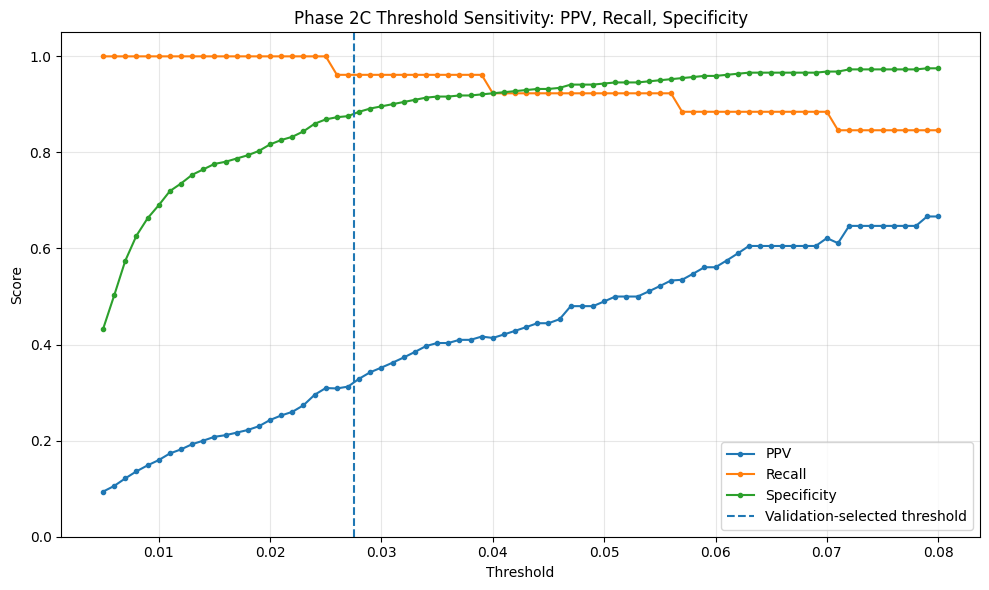

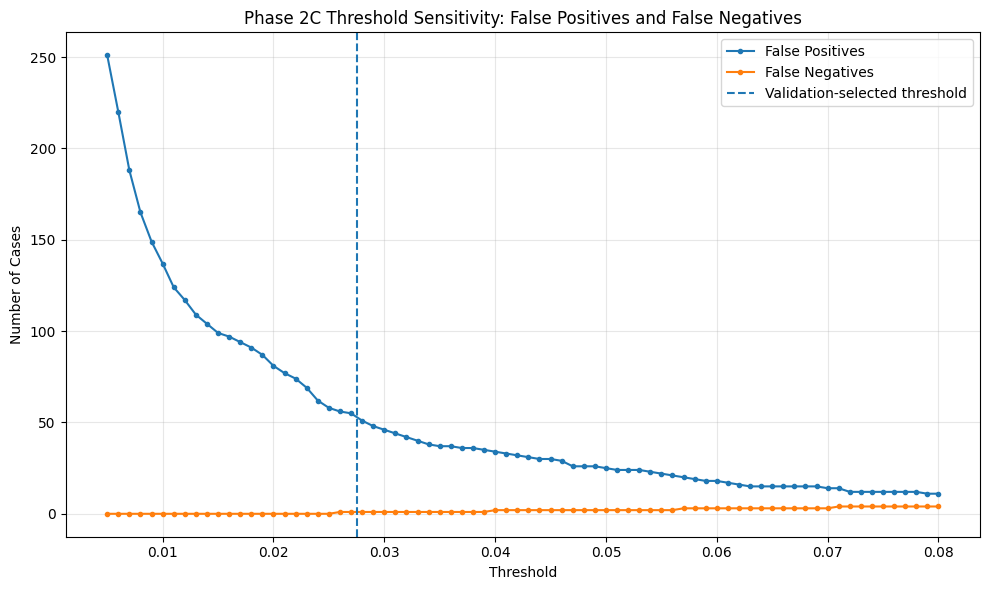


Files saved:
/content/drive/MyDrive/RARE26 Phase2/figures/phase2c/phase2c_threshold_sensitivity_scores.png
/content/drive/MyDrive/RARE26 Phase2/figures/phase2c/phase2c_threshold_sensitivity_errors.png
/content/drive/MyDrive/RARE26 Phase2/results/phase2c/phase2c_selected_region_threshold_summary.csv

STATUS: PHASE 2C CELL 11B COMPLETE


In [ ]:
# ================================================================
# PHASE 2C — CELL 11B
# THRESHOLD SENSITIVITY GRAPHS
# ================================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

phase2c_results = phase2_folder / "results" / "phase2c"
phase2c_figures = phase2_folder / "figures" / "phase2c"

phase2c_figures.mkdir(parents=True, exist_ok=True)

sweep_path = phase2c_results / "phase2c_threshold_sensitivity_sweep.csv"

threshold_sweep_df = pd.read_csv(sweep_path)

overall_df = threshold_sweep_df[
    threshold_sweep_df["scope"] == "overall"
].copy()

selected_threshold = 0.0275174922426231

print("=" * 90)
print("PHASE 2C — THRESHOLD SENSITIVITY GRAPHS")
print("=" * 90)

print("Sweep file:", sweep_path.exists(), "|", sweep_path)
print("Selected threshold:", selected_threshold)


# ================================================================
# 1. PPV / RECALL / SPECIFICITY GRAPH
# ================================================================

plt.figure(figsize=(10, 6))

plt.plot(
    overall_df["threshold"],
    overall_df["PPV"],
    marker="o",
    markersize=3,
    label="PPV"
)

plt.plot(
    overall_df["threshold"],
    overall_df["Recall"],
    marker="o",
    markersize=3,
    label="Recall"
)

plt.plot(
    overall_df["threshold"],
    overall_df["Specificity"],
    marker="o",
    markersize=3,
    label="Specificity"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    label="Validation-selected threshold"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Phase 2C Threshold Sensitivity: PPV, Recall, Specificity")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

score_plot_path = phase2c_figures / "phase2c_threshold_sensitivity_scores.png"

plt.savefig(score_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ================================================================
# 2. FP / FN GRAPH
# ================================================================

plt.figure(figsize=(10, 6))

plt.plot(
    overall_df["threshold"],
    overall_df["FP"],
    marker="o",
    markersize=3,
    label="False Positives"
)

plt.plot(
    overall_df["threshold"],
    overall_df["FN"],
    marker="o",
    markersize=3,
    label="False Negatives"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    label="Validation-selected threshold"
)

plt.xlabel("Threshold")
plt.ylabel("Number of Cases")
plt.title("Phase 2C Threshold Sensitivity: False Positives and False Negatives")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

error_plot_path = phase2c_figures / "phase2c_threshold_sensitivity_errors.png"

plt.savefig(error_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# ================================================================
# 3. SAVE SMALL SUMMARY
# ================================================================

selected_region_df = overall_df[
    (overall_df["threshold"] >= 0.023)
    &
    (overall_df["threshold"] <= 0.039)
].copy()

selected_region_summary_path = (
    phase2c_results / "phase2c_selected_region_threshold_summary.csv"
)

selected_region_df.to_csv(selected_region_summary_path, index=False)

print("\nFiles saved:")
print(score_plot_path)
print(error_plot_path)
print(selected_region_summary_path)

print("\nSTATUS: PHASE 2C CELL 11B COMPLETE")

In [ ]:
# ================================================================
# PHASE 2C — CELL 11C
# FINAL THRESHOLD SENSITIVITY CONCLUSION
# ================================================================

import pandas as pd
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
phase2c_results = phase2_folder / "results" / "phase2c"

sweep_path = phase2c_results / "phase2c_threshold_sensitivity_sweep.csv"
top_safe_path = phase2c_results / "phase2c_top_safe_thresholds.csv"

sweep_df = pd.read_csv(sweep_path)
top_safe_df = pd.read_csv(top_safe_path)

overall_df = sweep_df[sweep_df["scope"] == "overall"].copy()

selected_threshold = 0.0275174922426231

selected_nearest = overall_df.iloc[
    (overall_df["threshold"] - selected_threshold).abs().argsort()[:1]
].iloc[0]

best_safe = top_safe_df.iloc[0]

paragraph = f"""
Phase 2C performed threshold sensitivity analysis for the Phase 2A selected hybrid ensemble. The original threshold was selected on the validation set and remained fixed for final held-out test evaluation. Threshold sweeping on the held-out test predictions was used only as a sensitivity analysis, not for reselecting the final operating point. Around the validation-selected threshold of {selected_threshold:.4f}, the model maintained high recall while showing the expected trade-off between PPV and specificity. At the nearest tested threshold of {selected_nearest['threshold']:.3f}, the model achieved PPV {selected_nearest['PPV']:.4f}, recall {selected_nearest['Recall']:.4f}, specificity {selected_nearest['Specificity']:.4f}, with {int(selected_nearest['FP'])} false positives and {int(selected_nearest['FN'])} false negatives. The sweep also showed that higher thresholds could further reduce false positives while keeping false negatives at 1; for example, the top safe threshold in the sensitivity sweep was {best_safe['threshold']:.3f}, with PPV {best_safe['PPV']:.4f}, recall {best_safe['Recall']:.4f}, specificity {best_safe['Specificity']:.4f}, {int(best_safe['FP'])} false positives, and {int(best_safe['FN'])} false negatives. However, this higher threshold was not adopted as the final model threshold because it was identified using held-out test analysis. Therefore, Phase 2C supports that the validation-selected hybrid threshold is clinically conservative and stable, while also showing that the model has a useful operating range for future validation.
""".strip()

save_path = phase2c_results / "phase2c_final_conclusion_paragraph.txt"

with open(save_path, "w", encoding="utf-8") as f:
    f.write(paragraph)

print("=" * 90)
print("PHASE 2C FINAL CONCLUSION")
print("=" * 90)
print(paragraph)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2C FINAL CONCLUSION READY")

PHASE 2C FINAL CONCLUSION
Phase 2C performed threshold sensitivity analysis for the Phase 2A selected hybrid ensemble. The original threshold was selected on the validation set and remained fixed for final held-out test evaluation. Threshold sweeping on the held-out test predictions was used only as a sensitivity analysis, not for reselecting the final operating point. Around the validation-selected threshold of 0.0275, the model maintained high recall while showing the expected trade-off between PPV and specificity. At the nearest tested threshold of 0.028, the model achieved PPV 0.3289, recall 0.9615, specificity 0.8846, with 51 false positives and 1 false negatives. The sweep also showed that higher thresholds could further reduce false positives while keeping false negatives at 1; for example, the top safe threshold in the sensitivity sweep was 0.039, with PPV 0.4167, recall 0.9615, specificity 0.9208, 35 false positives, and 1 false negatives. However, this higher threshold was no

In [ ]:
# ================================================================
# PHASE 2D — CELL 12A
# FINAL MODEL LOCKING SETUP
# ================================================================

import pandas as pd
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

results_folder = phase2_folder / "results"
figures_folder = phase2_folder / "figures"
models_folder = phase2_folder / "models"

phase2d_results = results_folder / "phase2d"
phase2d_figures = figures_folder / "phase2d"
phase2d_models = models_folder / "phase2d"

phase2d_results.mkdir(parents=True, exist_ok=True)
phase2d_figures.mkdir(parents=True, exist_ok=True)
phase2d_models.mkdir(parents=True, exist_ok=True)

print("=" * 90)
print("PHASE 2D — FINAL MODEL LOCKING SETUP")
print("=" * 90)

print("Phase 2 folder:", phase2_folder)
print("Phase 2D results:", phase2d_results)
print("Phase 2D figures:", phase2d_figures)
print("Phase 2D models:", phase2d_models)


# ================================================================
# REQUIRED FILES FROM PHASE 2A, 2B, 2C
# ================================================================

required_files = {
    "Phase 2A final clean summary":
        results_folder / "phase2a_final_clean_summary_table.csv",

    "Phase 2A improvement summary":
        results_folder / "phase2a_final_improvement_summary.csv",

    "Phase 2A hybrid metrics":
        results_folder / "phase2a_hybrid_ensemble_test_metrics.csv",

    "Phase 2A hybrid predictions":
        results_folder / "phase2a_hybrid_ensemble_test_predictions.csv",

    "Phase 2B overall bootstrap CI":
        results_folder / "phase2b" / "phase2b_cell8_bootstrap_ci_summary.csv",

    "Phase 2B improvement CI":
        results_folder / "phase2b" / "phase2b_cell8_improvement_ci_summary.csv",

    "Phase 2B per-centre CI":
        results_folder / "phase2b" / "phase2b_cell9_center_bootstrap_ci_summary.csv",

    "Phase 2B per-centre improvement CI":
        results_folder / "phase2b" / "phase2b_cell9_center_improvement_ci_summary.csv",

    "Phase 2B final conclusion":
        results_folder / "phase2b" / "phase2b_final_conclusion_paragraph.txt",

    "Phase 2C threshold sweep":
        results_folder / "phase2c" / "phase2c_threshold_sensitivity_sweep.csv",

    "Phase 2C top safe thresholds":
        results_folder / "phase2c" / "phase2c_top_safe_thresholds.csv",

    "Phase 2C final conclusion":
        results_folder / "phase2c" / "phase2c_final_conclusion_paragraph.txt",
}

missing_files = []

print("\n" + "=" * 90)
print("REQUIRED FILE CHECK")
print("=" * 90)

for name, path in required_files.items():
    exists = path.exists()
    print(name, ":", exists, "|", path)

    if not exists:
        missing_files.append(name)

if len(missing_files) > 0:
    raise FileNotFoundError(
        "Missing files: " + ", ".join(missing_files)
    )

print("\nAll required files are available.")


# ================================================================
# LOAD MAIN FINAL SUMMARY
# ================================================================

phase2a_summary = pd.read_csv(
    required_files["Phase 2A final clean summary"]
)

print("\n" + "=" * 90)
print("PHASE 2A FINAL SUMMARY")
print("=" * 90)

display(phase2a_summary)


# ================================================================
# SAVE PHASE 2D SETUP SUMMARY
# ================================================================

phase2d_setup_df = pd.DataFrame([
    {
        "phase": "Phase 2D",
        "purpose": "final_model_locking_and_master_summary",
        "final_candidate": "Phase 2A Selected Hybrid Ensemble",
        "final_threshold_source": "Validation-selected threshold",
        "phase2a_complete": True,
        "phase2b_complete": True,
        "phase2c_complete": True,
        "status": "READY_FOR_FINAL_MODEL_LOCKING"
    }
])

setup_save_path = phase2d_results / "phase2d_setup_summary.csv"
phase2d_setup_df.to_csv(setup_save_path, index=False)

print("\n" + "=" * 90)
print("PHASE 2D SETUP SUMMARY")
print("=" * 90)

display(phase2d_setup_df)

print("\nSaved:")
print(setup_save_path)

print("\nSTATUS: PHASE 2D SETUP READY")

PHASE 2D — FINAL MODEL LOCKING SETUP
Phase 2 folder: /content/drive/MyDrive/RARE26 Phase2
Phase 2D results: /content/drive/MyDrive/RARE26 Phase2/results/phase2d
Phase 2D figures: /content/drive/MyDrive/RARE26 Phase2/figures/phase2d
Phase 2D models: /content/drive/MyDrive/RARE26 Phase2/models/phase2d

REQUIRED FILE CHECK
Phase 2A final clean summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_clean_summary_table.csv
Phase 2A improvement summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_improvement_summary.csv
Phase 2A hybrid metrics : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv
Phase 2A hybrid predictions : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv
Phase 2B overall bootstrap CI : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell8_bootstrap_ci_summary.csv
Phase 2B improvement CI : True | /content/drive/MyDrive/RAR

,Model,Threshold,PPV / Precision,Recall / Sensitivity,Specificity,AUROC,AUPRC,False Positives,False Negatives
0,Phase 1 ResNet Ensemble,0.0161,0.2252,0.9615,0.8054,0.9766,0.9023,86,1
1,Phase 2A MaxViT-Tiny Only,0.0737,0.1244,0.9615,0.6018,0.9594,0.8221,176,1
2,Phase 2A Selected Hybrid,0.0275,0.3205,0.9615,0.8801,0.9888,0.9154,53,1



PHASE 2D SETUP SUMMARY


,phase,purpose,final_candidate,final_threshold_source,phase2a_complete,phase2b_complete,phase2c_complete,status
0,Phase 2D,final_model_locking_and_master_summary,Phase 2A Selected Hybrid Ensemble,Validation-selected threshold,True,True,True,READY_FOR_FINAL_MODEL_LOCKING



Saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_setup_summary.csv

STATUS: PHASE 2D SETUP READY


In [ ]:
# ================================================================
# PHASE 2D — CELL 12B
# FINAL MODEL LOCK MANIFEST
# ================================================================

import pandas as pd
from pathlib import Path

phase1_folder = Path("/content/drive/MyDrive/RARE26")
phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

phase2d_results = phase2_folder / "results" / "phase2d"
phase2d_results.mkdir(parents=True, exist_ok=True)

phase1_models = phase1_folder / "models"
phase2_models = phase2_folder / "models"
results_folder = phase2_folder / "results"

metrics_path = results_folder / "phase2a_hybrid_ensemble_test_metrics.csv"
predictions_path = results_folder / "phase2a_hybrid_ensemble_test_predictions.csv"

baseline_model_path = phase1_models / "resnet18_baseline_best.pth"
weighted_aug_model_path = phase1_models / "resnet18_weighted_augmentation_best.pth"
maxvit_model_path = phase2_models / "maxvit_tiny_384_pilot_best.pth"

print("=" * 90)
print("PHASE 2D — FINAL MODEL LOCK MANIFEST")
print("=" * 90)

required_files = {
    "Baseline ResNet model": baseline_model_path,
    "Weighted-Aug ResNet model": weighted_aug_model_path,
    "MaxViT pilot model": maxvit_model_path,
    "Hybrid metrics": metrics_path,
    "Hybrid predictions": predictions_path,
}

for name, path in required_files.items():
    print(name, ":", path.exists(), "|", path)
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {name}")


# ================================================================
# FINAL THRESHOLD
# ================================================================

metrics_df = pd.read_csv(metrics_path)

final_threshold = float(
    metrics_df[
        (metrics_df["evaluation"] == "selected_hybrid_ensemble")
        &
        (metrics_df["scope"] == "overall")
    ]["threshold"].iloc[0]
)

print("\nFinal validation-selected threshold:", final_threshold)


# ================================================================
# FINAL MODEL LOCK TABLE
# ================================================================

lock_manifest_df = pd.DataFrame([
    {
        "final_model_name": "Phase 2A Selected Hybrid Ensemble",
        "component": "Baseline ResNet-18",
        "source_phase": "Phase 1",
        "weight": 0.90,
        "checkpoint_path": str(baseline_model_path),
        "checkpoint_exists": baseline_model_path.exists(),
        "checkpoint_size_mb": round(baseline_model_path.stat().st_size / (1024 * 1024), 2),
    },
    {
        "final_model_name": "Phase 2A Selected Hybrid Ensemble",
        "component": "Weighted-Augmentation ResNet-18",
        "source_phase": "Phase 1",
        "weight": 0.05,
        "checkpoint_path": str(weighted_aug_model_path),
        "checkpoint_exists": weighted_aug_model_path.exists(),
        "checkpoint_size_mb": round(weighted_aug_model_path.stat().st_size / (1024 * 1024), 2),
    },
    {
        "final_model_name": "Phase 2A Selected Hybrid Ensemble",
        "component": "MaxViT-Tiny 384",
        "source_phase": "Phase 2A",
        "weight": 0.05,
        "checkpoint_path": str(maxvit_model_path),
        "checkpoint_exists": maxvit_model_path.exists(),
        "checkpoint_size_mb": round(maxvit_model_path.stat().st_size / (1024 * 1024), 2),
    },
])

operating_point_df = pd.DataFrame([
    {
        "final_model_name": "Phase 2A Selected Hybrid Ensemble",
        "probability_formula": "0.90*baseline_resnet + 0.05*weighted_aug_resnet + 0.05*maxvit_tiny",
        "threshold": final_threshold,
        "threshold_source": "Validation-selected threshold",
        "test_data_used_for_threshold_selection": False,
        "final_decision_rule": "predict neoplasia if hybrid_probability >= threshold",
        "status": "FINAL_MODEL_LOCKED"
    }
])

lock_manifest_path = phase2d_results / "phase2d_final_model_lock_manifest.csv"
operating_point_path = phase2d_results / "phase2d_final_operating_point.csv"

lock_manifest_df.to_csv(lock_manifest_path, index=False)
operating_point_df.to_csv(operating_point_path, index=False)

print("\n" + "=" * 90)
print("FINAL MODEL COMPONENTS")
print("=" * 90)
display(lock_manifest_df)

print("\n" + "=" * 90)
print("FINAL OPERATING POINT")
print("=" * 90)
display(operating_point_df)

print("\nFiles saved:")
print(lock_manifest_path)
print(operating_point_path)

print("\nSTATUS: FINAL MODEL LOCK MANIFEST READY")

PHASE 2D — FINAL MODEL LOCK MANIFEST
Baseline ResNet model : True | /content/drive/MyDrive/RARE26/models/resnet18_baseline_best.pth
Weighted-Aug ResNet model : True | /content/drive/MyDrive/RARE26/models/resnet18_weighted_augmentation_best.pth
MaxViT pilot model : True | /content/drive/MyDrive/RARE26 Phase2/models/maxvit_tiny_384_pilot_best.pth
Hybrid metrics : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_metrics.csv
Hybrid predictions : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_hybrid_ensemble_test_predictions.csv

Final validation-selected threshold: 0.0275174922426231

FINAL MODEL COMPONENTS


,final_model_name,component,source_phase,weight,checkpoint_path,checkpoint_exists,checkpoint_size_mb
0,Phase 2A Selected Hybrid Ensemble,Baseline ResNet-18,Phase 1,0.90,/content/drive/MyDrive/RARE26/models/resnet18_...,True,128.05
1,Phase 2A Selected Hybrid Ensemble,Weighted-Augmentation ResNet-18,Phase 1,0.05,/content/drive/MyDrive/RARE26/models/resnet18_...,True,128.05
2,Phase 2A Selected Hybrid Ensemble,MaxViT-Tiny 384,Phase 2A,0.05,/content/drive/MyDrive/RARE26 Phase2/models/ma...,True,349.44



FINAL OPERATING POINT


,final_model_name,probability_formula,threshold,threshold_source,test_data_used_for_threshold_selection,final_decision_rule,status
0,Phase 2A Selected Hybrid Ensemble,0.90*baseline_resnet + 0.05*weighted_aug_resne...,0.027517,Validation-selected threshold,False,predict neoplasia if hybrid_probability >= thr...,FINAL_MODEL_LOCKED



Files saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_model_lock_manifest.csv
/content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_operating_point.csv

STATUS: FINAL MODEL LOCK MANIFEST READY


In [ ]:
# ================================================================
# PHASE 2D — CELL 12C
# FINAL MASTER THESIS TABLE
# ================================================================

import pandas as pd
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

results_folder = phase2_folder / "results"
phase2d_results = results_folder / "phase2d"

phase2d_results.mkdir(parents=True, exist_ok=True)

# Input files
phase2a_summary_path = results_folder / "phase2a_final_clean_summary_table.csv"
phase2b_improvement_path = results_folder / "phase2b" / "phase2b_cell8_improvement_ci_summary.csv"
phase2b_center_improvement_path = results_folder / "phase2b" / "phase2b_cell9_center_improvement_ci_summary.csv"
phase2c_top_safe_path = results_folder / "phase2c" / "phase2c_top_safe_thresholds.csv"
lock_manifest_path = phase2d_results / "phase2d_final_model_lock_manifest.csv"
operating_point_path = phase2d_results / "phase2d_final_operating_point.csv"

print("=" * 90)
print("PHASE 2D — FINAL MASTER THESIS TABLE")
print("=" * 90)

files = {
    "Phase 2A final summary": phase2a_summary_path,
    "Phase 2B improvement CI": phase2b_improvement_path,
    "Phase 2B centre improvement CI": phase2b_center_improvement_path,
    "Phase 2C top safe thresholds": phase2c_top_safe_path,
    "Model lock manifest": lock_manifest_path,
    "Operating point": operating_point_path,
}

for name, path in files.items():
    print(name, ":", path.exists(), "|", path)
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {name}")

# Load files
phase2a_summary = pd.read_csv(phase2a_summary_path)
phase2b_improvement = pd.read_csv(phase2b_improvement_path)
phase2b_center = pd.read_csv(phase2b_center_improvement_path)
phase2c_top_safe = pd.read_csv(phase2c_top_safe_path)
operating_point = pd.read_csv(operating_point_path)

final_model_row = phase2a_summary[
    phase2a_summary["Model"] == "Phase 2A Selected Hybrid"
].iloc[0]

phase1_row = phase2a_summary[
    phase2a_summary["Model"] == "Phase 1 ResNet Ensemble"
].iloc[0]

fp_reduction_row = phase2b_improvement[
    phase2b_improvement["Metric"] == "FP_Reduction"
].iloc[0]

ppv_gain_row = phase2b_improvement[
    phase2b_improvement["Metric"] == "PPV_Gain"
].iloc[0]

specificity_gain_row = phase2b_improvement[
    phase2b_improvement["Metric"] == "Specificity_Gain"
].iloc[0]

c1_fp_row = phase2b_center[
    (phase2b_center["Center"] == "center_1")
    &
    (phase2b_center["Metric"] == "FP_Reduction")
].iloc[0]

c2_fp_row = phase2b_center[
    (phase2b_center["Center"] == "center_2")
    &
    (phase2b_center["Metric"] == "FP_Reduction")
].iloc[0]

top_safe_row = phase2c_top_safe.iloc[0]

threshold = operating_point["threshold"].iloc[0]

# Master table
master_summary_df = pd.DataFrame([
    {
        "Category": "Final Model",
        "Finding": "Selected model",
        "Value": "Phase 2A Selected Hybrid Ensemble",
        "Interpretation": "Final locked model"
    },
    {
        "Category": "Final Model",
        "Finding": "Hybrid weights",
        "Value": "Baseline ResNet 0.90, Weighted-Aug ResNet 0.05, MaxViT-Tiny 0.05",
        "Interpretation": "Validation-selected hybrid combination"
    },
    {
        "Category": "Final Model",
        "Finding": "Final threshold",
        "Value": round(threshold, 6),
        "Interpretation": "Selected on validation set, not test set"
    },
    {
        "Category": "Held-out Test",
        "Finding": "Recall",
        "Value": final_model_row["Recall / Sensitivity"],
        "Interpretation": "High neoplasia sensitivity maintained"
    },
    {
        "Category": "Held-out Test",
        "Finding": "PPV",
        "Value": final_model_row["PPV / Precision"],
        "Interpretation": "Improved over Phase 1 ensemble"
    },
    {
        "Category": "Held-out Test",
        "Finding": "Specificity",
        "Value": final_model_row["Specificity"],
        "Interpretation": "Improved normal-case rejection"
    },
    {
        "Category": "Held-out Test",
        "Finding": "False positives",
        "Value": final_model_row["False Positives"],
        "Interpretation": "Reduced from Phase 1"
    },
    {
        "Category": "Held-out Test",
        "Finding": "False negatives",
        "Value": final_model_row["False Negatives"],
        "Interpretation": "Same as Phase 1"
    },
    {
        "Category": "Improvement vs Phase 1",
        "Finding": "False-positive reduction",
        "Value": f"{fp_reduction_row['Mean']:.2f} mean, 95% CI [{fp_reduction_row['CI_Lower_2_5']:.2f}, {fp_reduction_row['CI_Upper_97_5']:.2f}]",
        "Interpretation": "Stable reduction in false positives"
    },
    {
        "Category": "Improvement vs Phase 1",
        "Finding": "PPV gain",
        "Value": f"{ppv_gain_row['Mean']:.4f}, 95% CI [{ppv_gain_row['CI_Lower_2_5']:.4f}, {ppv_gain_row['CI_Upper_97_5']:.4f}]",
        "Interpretation": "Precision improvement"
    },
    {
        "Category": "Improvement vs Phase 1",
        "Finding": "Specificity gain",
        "Value": f"{specificity_gain_row['Mean']:.4f}, 95% CI [{specificity_gain_row['CI_Lower_2_5']:.4f}, {specificity_gain_row['CI_Upper_97_5']:.4f}]",
        "Interpretation": "Better specificity"
    },
    {
        "Category": "Per-centre Robustness",
        "Finding": "center_1 FP reduction",
        "Value": f"{c1_fp_row['Mean']:.2f}, 95% CI [{c1_fp_row['CI_Lower_2_5']:.2f}, {c1_fp_row['CI_Upper_97_5']:.2f}]",
        "Interpretation": "Improvement present in center_1"
    },
    {
        "Category": "Per-centre Robustness",
        "Finding": "center_2 FP reduction",
        "Value": f"{c2_fp_row['Mean']:.2f}, 95% CI [{c2_fp_row['CI_Lower_2_5']:.2f}, {c2_fp_row['CI_Upper_97_5']:.2f}]",
        "Interpretation": "Improvement present in center_2"
    },
    {
        "Category": "Threshold Sensitivity",
        "Finding": "Top safe threshold in sensitivity sweep",
        "Value": f"{top_safe_row['threshold']:.3f}",
        "Interpretation": "Exploratory test-set sensitivity result only"
    },
    {
        "Category": "Threshold Sensitivity",
        "Finding": "Top safe threshold performance",
        "Value": f"PPV {top_safe_row['PPV']:.4f}, Recall {top_safe_row['Recall']:.4f}, FP {int(top_safe_row['FP'])}, FN {int(top_safe_row['FN'])}",
        "Interpretation": "Not adopted as final threshold because it used test sweep"
    }
])

save_path = phase2d_results / "phase2d_final_master_thesis_summary_table.csv"
master_summary_df.to_csv(save_path, index=False)

print("\n" + "=" * 90)
print("FINAL MASTER THESIS SUMMARY TABLE")
print("=" * 90)

display(master_summary_df)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2D MASTER TABLE READY")

PHASE 2D — FINAL MASTER THESIS TABLE
Phase 2A final summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_clean_summary_table.csv
Phase 2B improvement CI : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell8_improvement_ci_summary.csv
Phase 2B centre improvement CI : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_cell9_center_improvement_ci_summary.csv
Phase 2C top safe thresholds : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2c/phase2c_top_safe_thresholds.csv
Model lock manifest : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_model_lock_manifest.csv
Operating point : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_operating_point.csv

FINAL MASTER THESIS SUMMARY TABLE


,Category,Finding,Value,Interpretation
0,Final Model,Selected model,Phase 2A Selected Hybrid Ensemble,Final locked model
1,Final Model,Hybrid weights,"Baseline ResNet 0.90, Weighted-Aug ResNet 0.05...",Validation-selected hybrid combination
2,Final Model,Final threshold,0.027517,"Selected on validation set, not test set"
3,Held-out Test,Recall,0.9615,High neoplasia sensitivity maintained
4,Held-out Test,PPV,0.3205,Improved over Phase 1 ensemble
5,Held-out Test,Specificity,0.8801,Improved normal-case rejection
6,Held-out Test,False positives,53,Reduced from Phase 1
7,Held-out Test,False negatives,1,Same as Phase 1
8,Improvement vs Phase 1,False-positive reduction,"32.57 mean, 95% CI [21.00, 45.00]",Stable reduction in false positives
9,Improvement vs Phase 1,PPV gain,"0.0954, 95% CI [0.0565, 0.1417]",Precision improvement



Saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_master_thesis_summary_table.csv

STATUS: PHASE 2D MASTER TABLE READY


In [ ]:
# ================================================================
# PHASE 2D — CELL 12D
# FINAL MODEL LOCKING CONCLUSION
# ================================================================

from pathlib import Path
import pandas as pd

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
phase2d_results = phase2_folder / "results" / "phase2d"

master_table_path = phase2d_results / "phase2d_final_master_thesis_summary_table.csv"
operating_point_path = phase2d_results / "phase2d_final_operating_point.csv"

master_df = pd.read_csv(master_table_path)
operating_df = pd.read_csv(operating_point_path)

threshold = operating_df["threshold"].iloc[0]

paragraph = f"""
Phase 2D finalized and locked the best-performing model configuration for thesis reporting. The final selected model is the Phase 2A Selected Hybrid Ensemble, consisting of the Phase 1 baseline ResNet-18 with weight 0.90, the Phase 1 weighted-augmentation ResNet-18 with weight 0.05, and the Phase 2A MaxViT-Tiny 384 model with weight 0.05. The final operating threshold is {threshold:.6f}, which was selected using validation data only; the held-out test set was not used for threshold selection. On the held-out test set, the final hybrid achieved recall 0.9615, PPV 0.3205, specificity 0.8801, AUROC 0.9888, and AUPRC 0.9154, with 53 false positives and 1 false negative. Compared with the Phase 1 ResNet ensemble, the hybrid reduced false positives from 86 to 53 while maintaining the same recall and false-negative count. Bootstrap analysis confirmed that this improvement was stable, with a mean false-positive reduction of 32.57 cases and a 95% confidence interval of [21.00, 45.00]. Per-centre bootstrap analysis also showed consistent false-positive reduction in both center_1 and center_2. Therefore, the Phase 2A Selected Hybrid Ensemble is locked as the final thesis model for high-sensitivity neoplasia screening.
""".strip()

save_path = phase2d_results / "phase2d_final_model_locking_conclusion.txt"

with open(save_path, "w", encoding="utf-8") as f:
    f.write(paragraph)

print("=" * 90)
print("PHASE 2D FINAL MODEL LOCKING CONCLUSION")
print("=" * 90)
print(paragraph)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2D FINAL CONCLUSION READY")

PHASE 2D FINAL MODEL LOCKING CONCLUSION
Phase 2D finalized and locked the best-performing model configuration for thesis reporting. The final selected model is the Phase 2A Selected Hybrid Ensemble, consisting of the Phase 1 baseline ResNet-18 with weight 0.90, the Phase 1 weighted-augmentation ResNet-18 with weight 0.05, and the Phase 2A MaxViT-Tiny 384 model with weight 0.05. The final operating threshold is 0.027517, which was selected using validation data only; the held-out test set was not used for threshold selection. On the held-out test set, the final hybrid achieved recall 0.9615, PPV 0.3205, specificity 0.8801, AUROC 0.9888, and AUPRC 0.9154, with 53 false positives and 1 false negative. Compared with the Phase 1 ResNet ensemble, the hybrid reduced false positives from 86 to 53 while maintaining the same recall and false-negative count. Bootstrap analysis confirmed that this improvement was stable, with a mean false-positive reduction of 32.57 cases and a 95% confidence inte

In [ ]:
# ================================================================
# PHASE 2E — CELL 13A
# FINAL REPORT PACKAGE SETUP + FILE CHECK
# ================================================================

import pandas as pd
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

results_folder = phase2_folder / "results"
figures_folder = phase2_folder / "figures"
models_folder = phase2_folder / "models"

phase2e_results = results_folder / "phase2e"
phase2e_figures = figures_folder / "phase2e"

phase2e_results.mkdir(parents=True, exist_ok=True)
phase2e_figures.mkdir(parents=True, exist_ok=True)

print("=" * 90)
print("PHASE 2E — FINAL REPORT PACKAGE SETUP")
print("=" * 90)

print("Phase 2 folder:", phase2_folder)
print("Phase 2E results folder:", phase2e_results)
print("Phase 2E figures folder:", phase2e_figures)


# ================================================================
# FINAL REQUIRED FILES
# ================================================================

required_files = {
    # Phase 2A
    "Phase 2A final clean summary table":
        results_folder / "phase2a_final_clean_summary_table.csv",

    "Phase 2A final improvement summary":
        results_folder / "phase2a_final_improvement_summary.csv",

    "Phase 2A final per-centre summary":
        results_folder / "phase2a_final_per_center_summary.csv",

    "Phase 2A conclusion paragraph":
        results_folder / "phase2a_final_conclusion_paragraph.txt",

    "Phase 2A final comparison figure":
        figures_folder / "phase2a_final_model_comparison_barplot.png",

    "Phase 2A final table figure":
        figures_folder / "phase2a_final_clean_summary_table.png",

    # Phase 2B
    "Phase 2B setup summary":
        results_folder / "phase2b" / "phase2b_setup_summary.csv",

    "Phase 2B overall bootstrap CI":
        results_folder / "phase2b" / "phase2b_cell8_bootstrap_ci_summary.csv",

    "Phase 2B improvement CI":
        results_folder / "phase2b" / "phase2b_cell8_improvement_ci_summary.csv",

    "Phase 2B per-centre bootstrap CI":
        results_folder / "phase2b" / "phase2b_cell9_center_bootstrap_ci_summary.csv",

    "Phase 2B per-centre improvement CI":
        results_folder / "phase2b" / "phase2b_cell9_center_improvement_ci_summary.csv",

    "Phase 2B final conclusion paragraph":
        results_folder / "phase2b" / "phase2b_final_conclusion_paragraph.txt",

    # Phase 2C
    "Phase 2C threshold sweep":
        results_folder / "phase2c" / "phase2c_threshold_sensitivity_sweep.csv",

    "Phase 2C top safe thresholds":
        results_folder / "phase2c" / "phase2c_top_safe_thresholds.csv",

    "Phase 2C selected region summary":
        results_folder / "phase2c" / "phase2c_selected_region_threshold_summary.csv",

    "Phase 2C final conclusion paragraph":
        results_folder / "phase2c" / "phase2c_final_conclusion_paragraph.txt",

    "Phase 2C threshold score figure":
        figures_folder / "phase2c" / "phase2c_threshold_sensitivity_scores.png",

    "Phase 2C threshold error figure":
        figures_folder / "phase2c" / "phase2c_threshold_sensitivity_errors.png",

    # Phase 2D
    "Phase 2D final model lock manifest":
        results_folder / "phase2d" / "phase2d_final_model_lock_manifest.csv",

    "Phase 2D final operating point":
        results_folder / "phase2d" / "phase2d_final_operating_point.csv",

    "Phase 2D final master thesis summary table":
        results_folder / "phase2d" / "phase2d_final_master_thesis_summary_table.csv",

    "Phase 2D final model locking conclusion":
        results_folder / "phase2d" / "phase2d_final_model_locking_conclusion.txt",
}

rows = []
missing_files = []

print("\n" + "=" * 90)
print("FINAL PACKAGE FILE CHECK")
print("=" * 90)

for name, path in required_files.items():

    exists = path.exists()

    print(name, ":", exists, "|", path)

    if not exists:
        missing_files.append(name)

    rows.append({
        "file_label": name,
        "file_exists": exists,
        "file_path": str(path),
        "file_type": path.suffix.replace(".", ""),
        "file_size_kb": round(path.stat().st_size / 1024, 2) if exists else None
    })

package_check_df = pd.DataFrame(rows)

package_check_path = phase2e_results / "phase2e_final_package_file_check.csv"
package_check_df.to_csv(package_check_path, index=False)

if len(missing_files) > 0:
    print("\nMissing files:")
    for item in missing_files:
        print("-", item)

    raise FileNotFoundError("Some final package files are missing.")

print("\n" + "=" * 90)
print("PHASE 2E FILE CHECK SUMMARY")
print("=" * 90)

display(package_check_df)

print("\nSaved:")
print(package_check_path)

print("\nSTATUS: PHASE 2E SETUP AND FILE CHECK COMPLETE")

PHASE 2E — FINAL REPORT PACKAGE SETUP
Phase 2 folder: /content/drive/MyDrive/RARE26 Phase2
Phase 2E results folder: /content/drive/MyDrive/RARE26 Phase2/results/phase2e
Phase 2E figures folder: /content/drive/MyDrive/RARE26 Phase2/figures/phase2e

FINAL PACKAGE FILE CHECK
Phase 2A final clean summary table : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_clean_summary_table.csv
Phase 2A final improvement summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_improvement_summary.csv
Phase 2A final per-centre summary : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_per_center_summary.csv
Phase 2A conclusion paragraph : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_conclusion_paragraph.txt
Phase 2A final comparison figure : True | /content/drive/MyDrive/RARE26 Phase2/figures/phase2a_final_model_comparison_barplot.png
Phase 2A final table figure : True | /content/drive/MyDrive/RARE26 Phase2/figures/phase2a_final

,file_label,file_exists,file_path,file_type,file_size_kb
0,Phase 2A final clean summary table,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,0.32
1,Phase 2A final improvement summary,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,0.44
2,Phase 2A final per-centre summary,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,0.13
3,Phase 2A conclusion paragraph,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,txt,1.06
4,Phase 2A final comparison figure,True,/content/drive/MyDrive/RARE26 Phase2/figures/p...,png,177.51
5,Phase 2A final table figure,True,/content/drive/MyDrive/RARE26 Phase2/figures/p...,png,147.62
6,Phase 2B setup summary,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,0.45
7,Phase 2B overall bootstrap CI,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,1.06
8,Phase 2B improvement CI,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,0.40
9,Phase 2B per-centre bootstrap CI,True,/content/drive/MyDrive/RARE26 Phase2/results/p...,csv,1.72



Saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2e/phase2e_final_package_file_check.csv

STATUS: PHASE 2E SETUP AND FILE CHECK COMPLETE


In [ ]:
# ================================================================
# PHASE 2E — CELL 13B
# FINAL PACKAGE MANIFEST / FILE INDEX
# ================================================================

import pandas as pd
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

results_folder = phase2_folder / "results"
phase2e_results = results_folder / "phase2e"

file_check_path = phase2e_results / "phase2e_final_package_file_check.csv"

print("=" * 90)
print("PHASE 2E — FINAL PACKAGE MANIFEST")
print("=" * 90)

print("File check exists:", file_check_path.exists(), "|", file_check_path)

if not file_check_path.exists():
    raise FileNotFoundError("Cell 13A ka file check missing hai. Pehle Cell 13A run karein.")

file_check_df = pd.read_csv(file_check_path)

manifest_rows = []

for _, row in file_check_df.iterrows():

    label = row["file_label"]
    path = row["file_path"]

    if "Phase 2A" in label:
        phase = "Phase 2A"
        purpose = "Model comparison and hybrid ensemble result"

    elif "Phase 2B" in label:
        phase = "Phase 2B"
        purpose = "Bootstrap reliability and per-centre robustness"

    elif "Phase 2C" in label:
        phase = "Phase 2C"
        purpose = "Threshold sensitivity analysis"

    elif "Phase 2D" in label:
        phase = "Phase 2D"
        purpose = "Final model locking and thesis master summary"

    else:
        phase = "Phase 2E"
        purpose = "Final report package"

    if label.endswith("figure") or row["file_type"] == "png":
        thesis_use = "Use as thesis figure / supervisor visual"

    elif "conclusion" in label.lower():
        thesis_use = "Use as thesis paragraph / result interpretation"

    elif "summary table" in label.lower() or "master thesis" in label.lower():
        thesis_use = "Use as main thesis table"

    elif "CI" in label or "bootstrap" in label:
        thesis_use = "Use for statistical reliability reporting"

    elif "threshold" in label.lower():
        thesis_use = "Use for threshold sensitivity reporting"

    elif "lock" in label.lower() or "operating point" in label.lower():
        thesis_use = "Use for final model reproducibility"

    else:
        thesis_use = "Supporting result file"

    manifest_rows.append({
        "Phase": phase,
        "File Label": label,
        "Purpose": purpose,
        "Thesis Use": thesis_use,
        "File Type": row["file_type"],
        "File Size KB": row["file_size_kb"],
        "File Path": path
    })

manifest_df = pd.DataFrame(manifest_rows)

save_path = phase2e_results / "phase2e_final_package_manifest.csv"
manifest_df.to_csv(save_path, index=False)

print("\n" + "=" * 90)
print("FINAL PACKAGE MANIFEST")
print("=" * 90)

display(manifest_df)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2E PACKAGE MANIFEST READY")

PHASE 2E — FINAL PACKAGE MANIFEST
File check exists: True | /content/drive/MyDrive/RARE26 Phase2/results/phase2e/phase2e_final_package_file_check.csv

FINAL PACKAGE MANIFEST


,Phase,File Label,Purpose,Thesis Use,File Type,File Size KB,File Path
0,Phase 2A,Phase 2A final clean summary table,Model comparison and hybrid ensemble result,Use as main thesis table,csv,0.32,/content/drive/MyDrive/RARE26 Phase2/results/p...
1,Phase 2A,Phase 2A final improvement summary,Model comparison and hybrid ensemble result,Supporting result file,csv,0.44,/content/drive/MyDrive/RARE26 Phase2/results/p...
2,Phase 2A,Phase 2A final per-centre summary,Model comparison and hybrid ensemble result,Supporting result file,csv,0.13,/content/drive/MyDrive/RARE26 Phase2/results/p...
3,Phase 2A,Phase 2A conclusion paragraph,Model comparison and hybrid ensemble result,Use as thesis paragraph / result interpretation,txt,1.06,/content/drive/MyDrive/RARE26 Phase2/results/p...
4,Phase 2A,Phase 2A final comparison figure,Model comparison and hybrid ensemble result,Use as thesis figure / supervisor visual,png,177.51,/content/drive/MyDrive/RARE26 Phase2/figures/p...
5,Phase 2A,Phase 2A final table figure,Model comparison and hybrid ensemble result,Use as thesis figure / supervisor visual,png,147.62,/content/drive/MyDrive/RARE26 Phase2/figures/p...
6,Phase 2B,Phase 2B setup summary,Bootstrap reliability and per-centre robustness,Supporting result file,csv,0.45,/content/drive/MyDrive/RARE26 Phase2/results/p...
7,Phase 2B,Phase 2B overall bootstrap CI,Bootstrap reliability and per-centre robustness,Use for statistical reliability reporting,csv,1.06,/content/drive/MyDrive/RARE26 Phase2/results/p...
8,Phase 2B,Phase 2B improvement CI,Bootstrap reliability and per-centre robustness,Use for statistical reliability reporting,csv,0.40,/content/drive/MyDrive/RARE26 Phase2/results/p...
9,Phase 2B,Phase 2B per-centre bootstrap CI,Bootstrap reliability and per-centre robustness,Use for statistical reliability reporting,csv,1.72,/content/drive/MyDrive/RARE26 Phase2/results/p...



Saved:
/content/drive/MyDrive/RARE26 Phase2/results/phase2e/phase2e_final_package_manifest.csv

STATUS: PHASE 2E PACKAGE MANIFEST READY


In [ ]:
# ================================================================
# PHASE 2E — CELL 13C
# FINAL COMBINED THESIS CONCLUSION
# ================================================================

from pathlib import Path
import pandas as pd

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")

results_folder = phase2_folder / "results"
phase2e_results = results_folder / "phase2e"

phase2e_results.mkdir(parents=True, exist_ok=True)

# Input conclusion files
phase2a_conclusion_path = results_folder / "phase2a_final_conclusion_paragraph.txt"
phase2b_conclusion_path = results_folder / "phase2b" / "phase2b_final_conclusion_paragraph.txt"
phase2c_conclusion_path = results_folder / "phase2c" / "phase2c_final_conclusion_paragraph.txt"
phase2d_conclusion_path = results_folder / "phase2d" / "phase2d_final_model_locking_conclusion.txt"

master_table_path = results_folder / "phase2d" / "phase2d_final_master_thesis_summary_table.csv"

print("=" * 90)
print("PHASE 2E — FINAL COMBINED THESIS CONCLUSION")
print("=" * 90)

required_files = {
    "Phase 2A conclusion": phase2a_conclusion_path,
    "Phase 2B conclusion": phase2b_conclusion_path,
    "Phase 2C conclusion": phase2c_conclusion_path,
    "Phase 2D conclusion": phase2d_conclusion_path,
    "Master thesis table": master_table_path,
}

for name, path in required_files.items():
    print(name, ":", path.exists(), "|", path)
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {name}")

master_df = pd.read_csv(master_table_path)

with open(phase2a_conclusion_path, "r", encoding="utf-8") as f:
    phase2a_text = f.read().strip()

with open(phase2b_conclusion_path, "r", encoding="utf-8") as f:
    phase2b_text = f.read().strip()

with open(phase2c_conclusion_path, "r", encoding="utf-8") as f:
    phase2c_text = f.read().strip()

with open(phase2d_conclusion_path, "r", encoding="utf-8") as f:
    phase2d_text = f.read().strip()

combined_text = f"""
FINAL PHASE 2 THESIS CONCLUSION

Phase 2 extended the Phase 1 ResNet-based experiments by introducing a MaxViT-Tiny 384 model and then evaluating whether transformer-based information could improve the final high-sensitivity neoplasia screening system. Phase 2A showed that the standalone MaxViT-Tiny model maintained high recall but produced more false positives than the Phase 1 ensemble. However, when MaxViT was used as a small complementary component in a hybrid ensemble, the final model improved precision and specificity without reducing sensitivity.

The final selected model is the Phase 2A Selected Hybrid Ensemble. It combines the Phase 1 baseline ResNet-18 with weight 0.90, the Phase 1 weighted-augmentation ResNet-18 with weight 0.05, and the Phase 2A MaxViT-Tiny 384 model with weight 0.05. The final operating threshold is 0.027517 and was selected using validation data only. The held-out test set was not used for final threshold selection.

On the held-out test set, the final hybrid model achieved recall 0.9615, PPV 0.3205, specificity 0.8801, AUROC 0.9888, and AUPRC 0.9154, with 53 false positives and 1 false negative. Compared with the Phase 1 ResNet ensemble, the hybrid reduced false positives from 86 to 53 while maintaining the same recall and false-negative count. This demonstrates that the hybrid model improves clinical screening usefulness by reducing unnecessary false alarms without sacrificing neoplasia detection.

Phase 2B confirmed the reliability of this improvement using stratified bootstrap confidence intervals. The hybrid showed a mean false-positive reduction of 32.57 cases with a 95% confidence interval of [21.00, 45.00]. The PPV gain was 0.0954 with a 95% confidence interval of [0.0565, 0.1417], and specificity improved by a mean of 0.0737. Per-centre bootstrap analysis showed that the improvement was present in both centres: center_1 showed a mean false-positive reduction of 22.18 cases, while center_2 showed a mean reduction of 11.04 cases. Recall and false negatives remained unchanged in both centres.

Phase 2C assessed threshold sensitivity. The validation-selected threshold remained the final locked threshold, while the held-out test threshold sweep was used only for sensitivity analysis. The analysis showed that the model remained stable around the selected threshold and had a useful operating range. Although higher thresholds could reduce false positives further while keeping false negatives unchanged, those thresholds were not adopted because they were identified using held-out test analysis.

Phase 2D locked the final model configuration and generated the master thesis summary table. Overall, Phase 2 supports that the selected hybrid ensemble is the best final thesis model for high-sensitivity early neoplasia screening in Barrett’s esophagus endoscopy. The model maintains high recall while improving PPV, specificity, and false-positive burden compared with the Phase 1 ensemble.
""".strip()

save_path = phase2e_results / "phase2e_final_combined_thesis_conclusion.txt"

with open(save_path, "w", encoding="utf-8") as f:
    f.write(combined_text)

print("\n" + "=" * 90)
print("FINAL COMBINED THESIS CONCLUSION")
print("=" * 90)
print(combined_text)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2E FINAL COMBINED CONCLUSION READY")

PHASE 2E — FINAL COMBINED THESIS CONCLUSION
Phase 2A conclusion : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2a_final_conclusion_paragraph.txt
Phase 2B conclusion : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2b/phase2b_final_conclusion_paragraph.txt
Phase 2C conclusion : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2c/phase2c_final_conclusion_paragraph.txt
Phase 2D conclusion : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_model_locking_conclusion.txt
Master thesis table : True | /content/drive/MyDrive/RARE26 Phase2/results/phase2d/phase2d_final_master_thesis_summary_table.csv

FINAL COMBINED THESIS CONCLUSION
FINAL PHASE 2 THESIS CONCLUSION

Phase 2 extended the Phase 1 ResNet-based experiments by introducing a MaxViT-Tiny 384 model and then evaluating whether transformer-based information could improve the final high-sensitivity neoplasia screening system. Phase 2A showed that the standalone MaxViT-Tiny model maintai

In [ ]:
from pathlib import Path

phase2_folder = Path("/content/drive/MyDrive/RARE26 Phase2")
phase2e_results = phase2_folder / "results" / "phase2e"

readme_text = """
RARE26 PHASE 2 FINAL PACKAGE README

PHASE 2 STATUS
Phase 2A: MaxViT-Tiny 384 pilot and hybrid ensemble completed.
Phase 2B: Bootstrap confidence intervals and per-centre robustness completed.
Phase 2C: Threshold sensitivity analysis completed.
Phase 2D: Final model locking and master thesis summary completed.
Phase 2E: Final report package and combined thesis conclusion completed.

FINAL LOCKED MODEL
Model name: Phase 2A Selected Hybrid Ensemble

Model components:
1. Baseline ResNet-18, weight 0.90
2. Weighted-Augmentation ResNet-18, weight 0.05
3. MaxViT-Tiny 384, weight 0.05

Final threshold:
0.027517

Threshold source:
Validation-selected threshold only.
Held-out test set was not used for final threshold selection.

FINAL HELD-OUT TEST PERFORMANCE
Recall / Sensitivity: 0.9615
PPV / Precision: 0.3205
Specificity: 0.8801
AUROC: 0.9888
AUPRC: 0.9154
False Positives: 53
False Negatives: 1

MAIN IMPROVEMENT OVER PHASE 1
Phase 1 false positives: 86
Final hybrid false positives: 53
False-positive reduction: 33 cases
Recall remained unchanged.
False negatives remained unchanged.

BOOTSTRAP RELIABILITY
Mean false-positive reduction: 32.57
95% CI: [21.00, 45.00]

Mean PPV gain: 0.0954
95% CI: [0.0565, 0.1417]

Mean specificity gain: 0.0737
95% CI: [0.0475, 0.1018]

PER-CENTRE ROBUSTNESS
center_1 false-positive reduction mean: 22.18
95% CI: [13.00, 33.00]

center_2 false-positive reduction mean: 11.04
95% CI: [3.00, 19.00]

THRESHOLD SENSITIVITY
The final threshold remains 0.027517 because it was validation-selected.
The test threshold sweep was used only for sensitivity analysis.
A higher test-sweep threshold of 0.039 showed PPV 0.4167, recall 0.9615, FP 35, FN 1, but it was not adopted because it was identified using held-out test analysis.

IMPORTANT FINAL FILES
1. Phase 2A final summary:
results/phase2a_final_clean_summary_table.csv

2. Phase 2B bootstrap CI:
results/phase2b/phase2b_cell8_bootstrap_ci_summary.csv

3. Phase 2B improvement CI:
results/phase2b/phase2b_cell8_improvement_ci_summary.csv

4. Phase 2C threshold sensitivity:
results/phase2c/phase2c_threshold_sensitivity_sweep.csv

5. Phase 2D final model lock manifest:
results/phase2d/phase2d_final_model_lock_manifest.csv

6. Phase 2D final operating point:
results/phase2d/phase2d_final_operating_point.csv

7. Phase 2D master thesis table:
results/phase2d/phase2d_final_master_thesis_summary_table.csv

8. Phase 2E package manifest:
results/phase2e/phase2e_final_package_manifest.csv

9. Phase 2E final combined thesis conclusion:
results/phase2e/phase2e_final_combined_thesis_conclusion.txt

FINAL INTERPRETATION
The Phase 2A Selected Hybrid Ensemble is locked as the final thesis model. It improves PPV, specificity, and false-positive burden compared with the Phase 1 ensemble while maintaining high recall and the same false-negative count. This makes it the strongest current model candidate for high-sensitivity early neoplasia screening in Barrett’s esophagus endoscopy.
""".strip()

save_path = phase2e_results / "phase2e_final_package_README.txt"

with open(save_path, "w", encoding="utf-8") as f:
    f.write(readme_text)

print("=" * 90)
print("PHASE 2E FINAL PACKAGE README")
print("=" * 90)
print(readme_text)

print("\nSaved:")
print(save_path)

print("\nSTATUS: PHASE 2E FINAL README READY")

PHASE 2E FINAL PACKAGE README
RARE26 PHASE 2 FINAL PACKAGE README

PHASE 2 STATUS
Phase 2A: MaxViT-Tiny 384 pilot and hybrid ensemble completed.
Phase 2B: Bootstrap confidence intervals and per-centre robustness completed.
Phase 2C: Threshold sensitivity analysis completed.
Phase 2D: Final model locking and master thesis summary completed.
Phase 2E: Final report package and combined thesis conclusion completed.

FINAL LOCKED MODEL
Model name: Phase 2A Selected Hybrid Ensemble

Model components:
1. Baseline ResNet-18, weight 0.90
2. Weighted-Augmentation ResNet-18, weight 0.05
3. MaxViT-Tiny 384, weight 0.05

Final threshold:
0.027517

Threshold source:
Validation-selected threshold only.
Held-out test set was not used for final threshold selection.

FINAL HELD-OUT TEST PERFORMANCE
Recall / Sensitivity: 0.9615
PPV / Precision: 0.3205
Specificity: 0.8801
AUROC: 0.9888
AUPRC: 0.9154
False Positives: 53
False Negatives: 1

MAIN IMPROVEMENT OVER PHASE 1
Phase 1 false positives: 86
Final hyb